# proSIM - SIM misuse detection: model training

Trains and evaluates three models on the synthetic CDR data from generator v3 (one row per SIM per day, plus the
call and SMS event records):

| Model | Type | Role |
|---|---|---|
| **Random Forest** | Supervised (multiclass) | Main detector: classifies each SIM-day as `normal` or one of seven misuse types: `unauthorized_sharing`, `data_reselling`, `ghost_usage`, `inactive_billing`, `call_abuse`, `sim_box`, `bulk_sms` |
| **Isolation Forest (data)** | Unsupervised | Safety net on the 48 data and billing features: flags unusual data use without using labels |
| **Isolation Forest (calls/SMS)** | Unsupervised | Safety net on the call and SMS features, scored as a 3-day average: flags unusual calling or texting |

Each section matches an issue in the **ML Training** milestone. Kernel: **proSIM (ml-service venv)**.

## 1. Setup and load data  (issue #1)

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

SEED = 42
np.random.seed(SEED)

# Locate the ml-training folder whether the kernel starts in notebooks/ or elsewhere.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and p.name == "ml-training")
DATA_DIR = ROOT / "data"
REPORTS_DIR = ROOT / "reports"
MODELS_DIR = ROOT.parent / "ml-service" / "models"
REPORTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("Data:", DATA_DIR)

scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.5.4
Data: C:\Users\user\Downloads\proSIM\ml-training\data


In [2]:
agg = pd.read_csv(DATA_DIR / "synthetic_cdr_daily_agg.csv")
labels = pd.read_csv(DATA_DIR / "synthetic_cdr_daily_labels.csv")

df = agg.merge(labels, on=["sim_id", "date"], how="left", validate="one_to_one")
assert df["label"].notna().all(), "every SIM-day must have a label"
df = df.sort_values(["sim_id", "date"]).reset_index(drop=True)

print(f"{len(df):,} SIM-days | {df.sim_id.nunique():,} SIMs | {df.date.min()} to {df.date.max()}")
df.head()

90,000 SIM-days | 1,000 SIMs | 2025-01-01 to 2025-03-31


,sim_id,date,total_download_mb,total_upload_mb,session_count,total_duration_s,hotspot_flag_count,geo_flag_count,roaming_sessions,unique_towers,...,offpeak_mb,max_session_mb,total_mb,billed_mb,tier,voice_minutes_used,sms_count,voice_minutes_remaining,sms_remaining,label
0,0,2025-01-01,342.12950,172.973200,6,910,0,0,0,2,...,84.6194,170.337700,515.10266,515.103,professional,0.000,2,200.00,133,normal
1,0,2025-01-02,358.46298,105.733894,4,859,0,0,0,1,...,0.0000,188.930390,464.19687,464.197,professional,0.000,0,200.00,133,normal
2,0,2025-01-03,233.34570,233.457500,6,1205,0,0,0,2,...,0.0000,234.102510,466.80322,466.803,professional,1.083,1,198.92,132,normal
3,0,2025-01-04,234.00330,39.758400,7,949,0,0,0,3,...,0.0000,221.097200,273.76170,273.762,professional,7.283,1,191.63,131,normal
4,0,2025-01-05,208.66790,56.779900,10,2863,0,0,0,3,...,0.0000,102.558395,265.44778,265.448,professional,2.050,1,189.58,130,normal


### 1.1 Call and SMS records
The daily file has only call minutes and an SMS count. Call and SMS misuse shows in *who* is called, *when* and for
*how long*, so per-day call/SMS features are built from the event records (`synthetic_cdr_sessions.csv`). As in
section 3, every value for a day uses only that day and earlier days: "new number" means a number this SIM had never
called or texted on any earlier day.

In [3]:
SESSIONS_FILE = DATA_DIR / "synthetic_cdr_sessions.csv"   # about 90 MB, gitignored like the other data files


def load_call_events(path):
    """Voice and SMS events with the hour of day and the destination number without '+'."""
    s = pd.read_csv(path, usecols=["sim_id", "session_timestamp", "session_duration", "event_type",
                                   "call_destination"], dtype={"call_destination": str})
    s = s[s["event_type"].isin(["Voice", "SMS"])].copy()
    ts = pd.to_datetime(s["session_timestamp"])
    s["date"] = ts.dt.strftime("%Y-%m-%d")
    s["h"] = ts.dt.hour
    s["dest"] = s["call_destination"].fillna("").str.lstrip("+")
    return s[["sim_id", "date", "h", "event_type", "session_duration", "dest"]].reset_index(drop=True)


def build_call_features(ev, data):
    """Call/SMS features per SIM-day, aligned with the rows of `data` (needs its sim_id and date columns)."""
    ev = ev.copy()
    ev["offpeak"] = ((ev["h"] >= 22) | (ev["h"] < 7)).astype(float)
    ev["intl"] = (~ev["dest"].str.startswith("254")).astype(float)
    ev["short"] = (ev["session_duration"] < 10).astype(float)
    ev["long"] = (ev["session_duration"] >= 300).astype(float)
    ev["new"] = (ev["date"] == ev.groupby(["sim_id", "dest"])["date"].transform("min")).astype(float)
    key = ["sim_id", "date"]
    v, m = ev[ev["event_type"] == "Voice"], ev[ev["event_type"] == "SMS"]
    calls = v.groupby(key).agg(
        calls=("dest", "size"), call_minutes=("session_duration", "sum"), mean_call_s=("session_duration", "mean"),
        short_call_share=("short", "mean"), long_call_share=("long", "mean"), offpeak_call_share=("offpeak", "mean"),
        intl_call_share=("intl", "mean"), new_call_share=("new", "mean"), _distinct=("dest", "nunique"))
    calls["call_minutes"] /= 60
    calls["repeat_call_share"] = 1 - calls.pop("_distinct") / calls["calls"]
    texts = m.groupby(key).agg(
        sms=("dest", "size"), offpeak_sms_share=("offpeak", "mean"), intl_sms_share=("intl", "mean"),
        new_sms_share=("new", "mean"), _distinct=("dest", "nunique"))
    texts["repeat_sms_share"] = 1 - texts.pop("_distinct") / texts["sms"]

    cf = (data[key].merge(calls.reset_index(), on=key, how="left")
          .merge(texts.reset_index(), on=key, how="left").fillna(0.0))
    cf.index = data.index
    cf = cf.sort_values(key)
    for c in ["calls", "call_minutes", "sms"]:   # change vs the SIM's own past (shift(1): today excluded)
        past = cf.groupby("sim_id")[c].shift(1)
        med14 = past.groupby(cf["sim_id"]).rolling(14, min_periods=3).median().reset_index(level=0, drop=True)
        medlt = past.groupby(cf["sim_id"]).expanding(min_periods=3).median().reset_index(level=0, drop=True)
        cf[f"{c}_vs_baseline"] = (cf[c] / (med14 + 1)).fillna(1.0)
        cf[f"{c}_vs_longterm"] = (cf[c] / (medlt + 1)).fillna(1.0)
    return cf.drop(columns=key).astype(float).loc[data.index]


EV = load_call_events(SESSIONS_FILE)
CF = build_call_features(EV, df)
CALL_FEATURES = list(CF.columns)
print(f"{len(EV):,} voice/SMS events -> {len(CALL_FEATURES)} call/SMS features per SIM-day:")
print(", ".join(CALL_FEATURES))

462,119 voice/SMS events -> 20 call/SMS features per SIM-day:
calls, call_minutes, mean_call_s, short_call_share, long_call_share, offpeak_call_share, intl_call_share, new_call_share, repeat_call_share, sms, offpeak_sms_share, intl_sms_share, new_sms_share, repeat_sms_share, calls_vs_baseline, calls_vs_longterm, call_minutes_vs_baseline, call_minutes_vs_longterm, sms_vs_baseline, sms_vs_longterm


In [4]:
# Columns and types, to plan feature engineering
df.dtypes.to_frame("dtype").T

,sim_id,date,total_download_mb,total_upload_mb,session_count,total_duration_s,hotspot_flag_count,geo_flag_count,roaming_sessions,unique_towers,...,offpeak_mb,max_session_mb,total_mb,billed_mb,tier,voice_minutes_used,sms_count,voice_minutes_remaining,sms_remaining,label
dtype,int64,str,float64,float64,int64,int64,int64,int64,int64,int64,...,float64,float64,float64,float64,str,float64,int64,float64,int64,str


## 2. Exploratory data analysis  (issue #2)

- [x] Label distribution table and chart (about 5% misuse)
- [x] Compare usage patterns of each misuse type against normal
- [x] Check and document that `billed_mb > total_mb` exactly separates inactive billing

Figures are saved to `reports/` for the write-up.

### 2.1 Data quality

In [5]:
# Class order and colours, reused by every chart in this notebook
CLASS_ORDER = ["normal", "unauthorized_sharing", "data_reselling", "ghost_usage", "inactive_billing",
               "call_abuse", "sim_box", "bulk_sms"]
MISUSE = CLASS_ORDER[1:]
DATA_TYPES, CALL_TYPES = MISUSE[:4], MISUSE[4:]
SHORT = {"normal": "normal", "unauthorized_sharing": "sharing", "data_reselling": "reselling",
         "ghost_usage": "ghost", "inactive_billing": "inactive\nbilling", "call_abuse": "call\nabuse",
         "sim_box": "SIM-box", "bulk_sms": "bulk\nSMS"}
CLASS_COLORS = {"normal": "#9a9893", "unauthorized_sharing": "#2a78d6", "data_reselling": "#eb6834",
                "ghost_usage": "#1baf7a", "inactive_billing": "#eda100", "call_abuse": "#6250d6",
                "sim_box": "#d6457a", "bulk_sms": "#1a9bb0"}

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#b8b6b0", "axes.labelcolor": "#52514e", "axes.titlesize": 11,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
})

def savefig(fig, name):
    fig.savefig(REPORTS_DIR / name, dpi=150, bbox_inches="tight")

numeric = df.select_dtypes("number")
days_per_sim = df.groupby("sim_id").size()
negatives = (numeric < 0).sum()
print("Missing values:              ", int(df.isna().sum().sum()))
print("Duplicate (sim_id, date) rows:", int(df.duplicated(["sim_id", "date"]).sum()))
print("Days per SIM:                 ", days_per_sim.min(), "to", days_per_sim.max())
print("Columns with negative values: ", negatives[negatives > 0].to_dict() or "none")

Missing values:               0
Duplicate (sim_id, date) rows: 0
Days per SIM:                  90 to 90
Columns with negative values:  {'voice_minutes_remaining': 4419, 'sms_remaining': 1250}


### 2.2 Label distribution

In [6]:
counts = df["label"].value_counts().reindex(CLASS_ORDER)
sims_affected = df.groupby("label")["sim_id"].nunique().reindex(CLASS_ORDER)
dist = pd.DataFrame({
    "SIM-days": counts,
    "share of days (%)": (100 * counts / len(df)).round(2),
    "SIMs affected": sims_affected,
})
dist.loc["normal", "SIMs affected"] = np.nan  # every SIM has normal days

misuse_sims = df.loc[df.label != "normal", "sim_id"].nunique()
print(f"Misuse days: {(df.label != 'normal').mean():.2%} of all SIM-days")
print(f"SIMs with at least one misuse day: {misuse_sims} of {df.sim_id.nunique()}")
dist

Misuse days: 6.67% of all SIM-days
SIMs with at least one misuse day: 401 of 1000


,SIM-days,share of days (%),SIMs affected
label,,,
normal,83995,93.33,NaN
unauthorized_sharing,1636,1.82,116.0
data_reselling,950,1.06,100.0
ghost_usage,1350,1.50,89.0
inactive_billing,1024,1.14,57.0
call_abuse,382,0.42,43.0
sim_box,489,0.54,36.0
bulk_sms,174,0.19,29.0


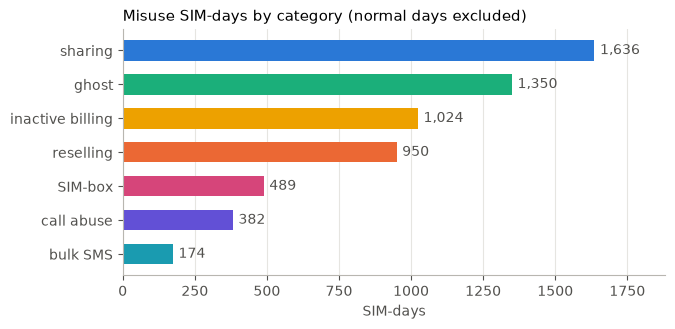

In [7]:
m = dist.loc[MISUSE, "SIM-days"].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh([SHORT[c].replace("\n", " ") for c in m.index], m.values, height=0.6,
               color=[CLASS_COLORS[c] for c in m.index])
ax.bar_label(bars, labels=[f"{v:,}" for v in m.values], padding=4, color="#52514e")
ax.set_xlabel("SIM-days")
ax.set_title("Misuse SIM-days by category (normal days excluded)", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, m.max() * 1.15)
savefig(fig, "eda_label_distribution.png")
plt.show()

### 2.3 Misuse episodes
Each misuse is an *episode*: a run of consecutive days on one SIM.

In [8]:
episodes = pd.read_csv(DATA_DIR / "synthetic_cdr_labels.csv")
ep = episodes.groupby("category")["duration_days"].agg(
    episodes="count", median_days="median", min_days="min", max_days="max").reindex(MISUSE)
multi = episodes.groupby("sim_id").size()
print(f"{len(episodes)} episodes on {episodes.sim_id.nunique()} SIMs; "
      f"{(multi > 1).sum()} SIMs have more than one episode")
ep

480 episodes on 401 SIMs; 70 SIMs have more than one episode


,episodes,median_days,min_days,max_days
category,,,,
unauthorized_sharing,121,10.0,1,71
data_reselling,105,7.0,1,48
ghost_usage,89,11.0,1,66
inactive_billing,57,13.0,1,72
call_abuse,43,7.0,1,31
sim_box,36,8.5,1,67
bulk_sms,29,4.0,1,21


### 2.4 How each misuse type differs from normal usage
Medians per class. Shares are computed here only for exploration; they are built properly in section 3.

In [9]:
eda = df.join(CF)  # daily columns + call/SMS features (section 1.1)
eps = 1e-6
eda["upload_share"] = eda["total_upload_mb"] / (eda["total_mb"] + eps)
eda["offpeak_share"] = eda["offpeak_mb"] / (eda["total_mb"] + eps)
eda["mb_per_session"] = eda["total_mb"] / (eda["session_count"] + eps)
eda["billed_minus_used_mb"] = eda["billed_mb"] - eda["total_mb"]

COMPARE = ["total_mb", "total_upload_mb", "upload_share", "session_count", "mb_per_session",
           "max_session_mb", "hotspot_flag_count", "unique_towers", "geo_flag_count",
           "roaming_sessions", "apn_public_count", "offpeak_share", "billed_minus_used_mb",
           "calls", "call_minutes", "mean_call_s", "new_call_share", "intl_call_share",
           "repeat_call_share", "sms", "new_sms_share"]
medians = eda.groupby("label")[COMPARE].median().reindex(CLASS_ORDER).T
medians.columns = [SHORT[c].replace("\n", " ") for c in medians.columns]
medians.round(2)

,normal,sharing,reselling,ghost,inactive billing,call abuse,SIM-box,bulk SMS
total_mb,393.55,1073.93,546.77,13.03,0.00,330.98,77.40,472.82
total_upload_mb,112.69,312.78,162.55,3.81,0.00,94.04,21.13,143.09
upload_share,0.29,0.30,0.30,0.29,0.00,0.30,0.30,0.29
session_count,9.00,9.00,8.00,6.00,5.00,14.00,64.00,38.50
mb_per_session,43.80,112.43,67.57,2.18,0.00,22.92,1.01,10.47
max_session_mb,180.48,521.12,274.24,6.22,0.00,150.68,33.55,212.53
hotspot_flag_count,0.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00
unique_towers,2.00,3.00,2.00,2.00,2.00,3.00,3.00,3.00
geo_flag_count,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
roaming_sessions,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


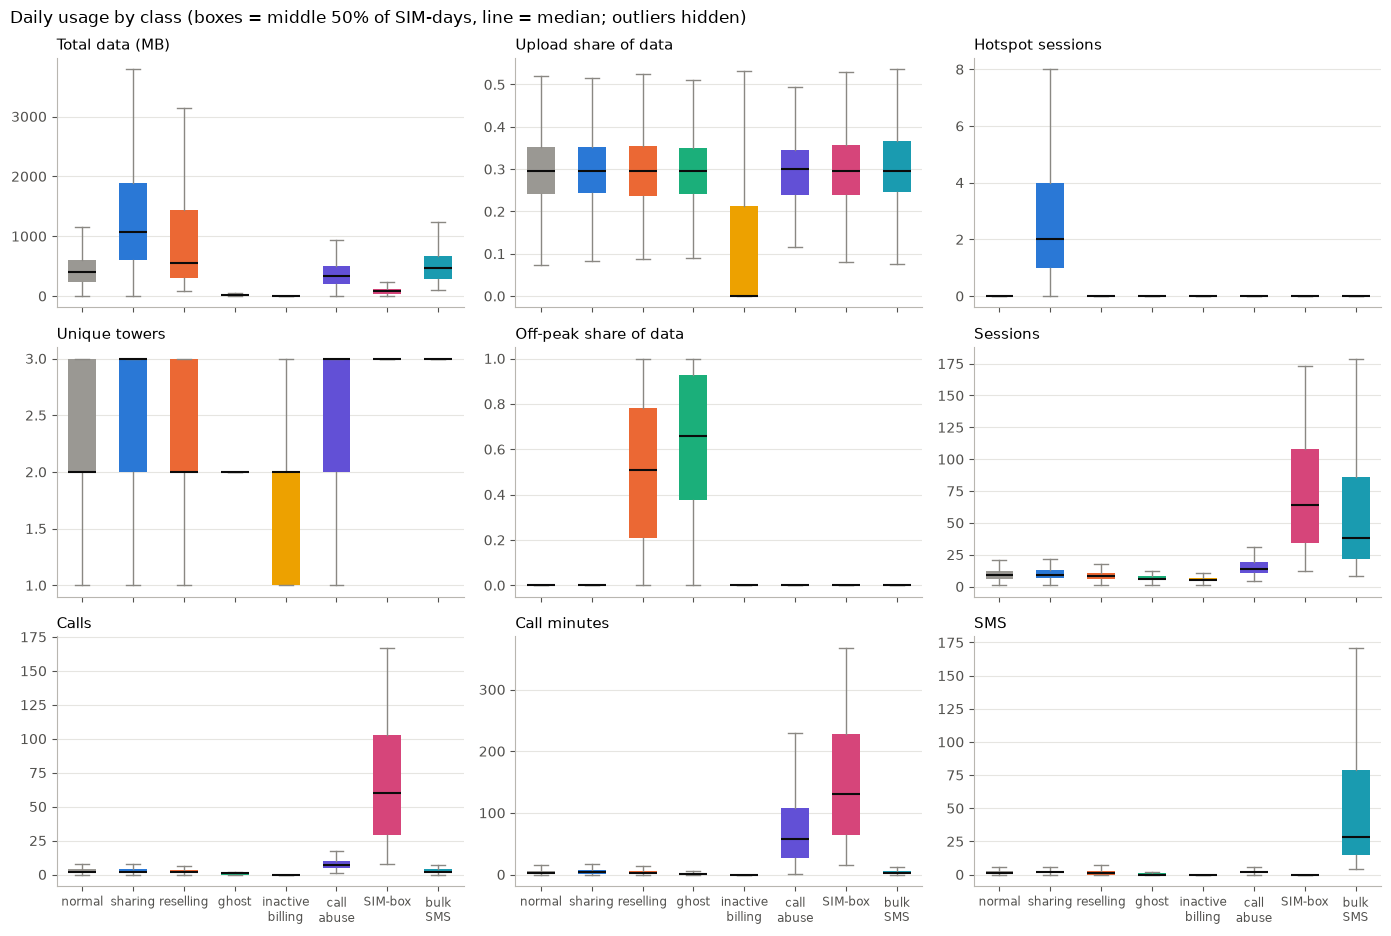

In [10]:
PANELS = [("total_mb", "Total data (MB)"), ("upload_share", "Upload share of data"),
          ("hotspot_flag_count", "Hotspot sessions"), ("unique_towers", "Unique towers"),
          ("offpeak_share", "Off-peak share of data"), ("session_count", "Sessions"),
          ("calls", "Calls"), ("call_minutes", "Call minutes"), ("sms", "SMS")]

fig, axes = plt.subplots(3, 3, figsize=(14, 9.5), sharex=True)
for ax, (col, title) in zip(axes.flat, PANELS):
    data = [eda.loc[eda.label == c, col].values for c in CLASS_ORDER]
    bp = ax.boxplot(data, widths=0.55, showfliers=False, patch_artist=True,
                    medianprops={"color": "#0b0b0b", "linewidth": 1.5},
                    whiskerprops={"color": "#8a8883"}, capprops={"color": "#8a8883"},
                    boxprops={"linewidth": 0})
    for patch, c in zip(bp["boxes"], CLASS_ORDER):
        patch.set_facecolor(CLASS_COLORS[c])
    ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)
for ax in axes[-1]:
    ax.set_xticks(range(1, len(CLASS_ORDER) + 1), [SHORT[c] for c in CLASS_ORDER], fontsize=8.5)
fig.suptitle("Daily usage by class (boxes = middle 50% of SIM-days, line = median; outliers hidden)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
savefig(fig, "eda_usage_by_class.png")
plt.show()

### 2.5 Misuse as a change in a SIM's own behaviour
One example SIM per misuse type, with the misuse episode shaded: daily data use for the data types, and call minutes, calls or SMS for the call types. Comparing a day with the same SIM's recent past is the idea behind the baseline features in section 3.

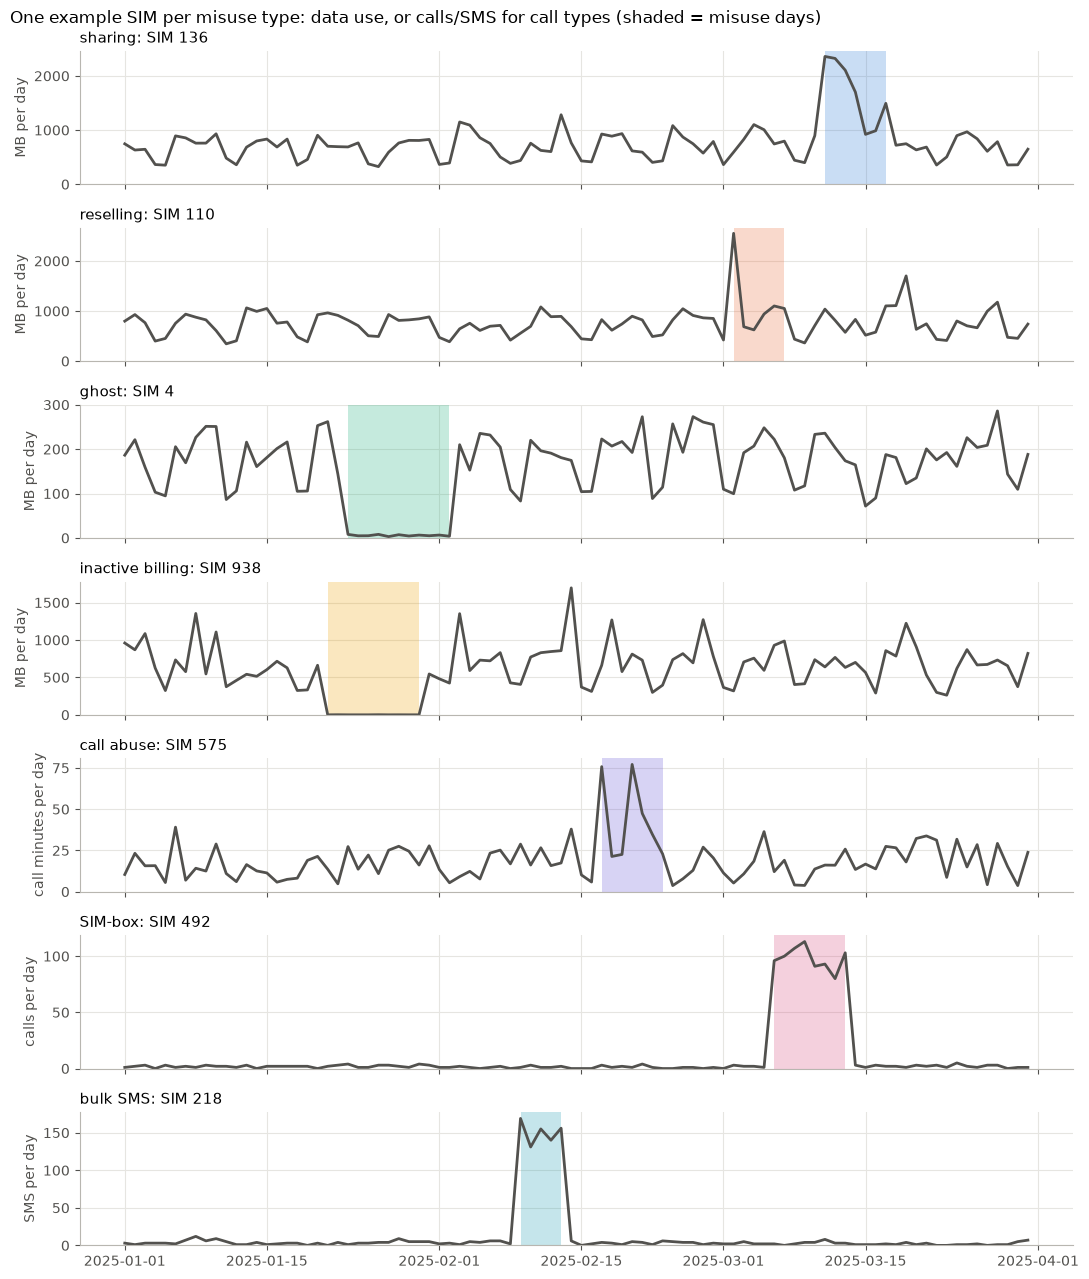

In [11]:
def pick_example(category):
    """A SIM whose episode of this type starts after day 20 (so there is history before it)."""
    cand = episodes[(episodes.category == category) & (episodes.start_day >= 20)].copy()
    cand["gap"] = (cand.duration_days - cand.duration_days.median()).abs()
    return int(cand.sort_values(["gap", "sim_id"]).iloc[0].sim_id)

SERIES = {"call_abuse": ("call_minutes", "call minutes per day"), "sim_box": ("calls", "calls per day"),
          "bulk_sms": ("sms", "SMS per day")}   # data types: ("total_mb", "MB per day")
fig, axes = plt.subplots(len(MISUSE), 1, figsize=(11, 13), sharex=True)
for ax, cat in zip(axes, MISUSE):
    sim = pick_example(cat)
    col, unit = SERIES.get(cat, ("total_mb", "MB per day"))
    s = eda[eda.sim_id == sim].copy()
    s["date"] = pd.to_datetime(s["date"])
    ax.plot(s["date"], s[col], color="#52514e", linewidth=2)
    in_ep = s["label"] == cat
    ax.fill_between(s["date"], 0, 1, where=in_ep, transform=ax.get_xaxis_transform(),
                    color=CLASS_COLORS[cat], alpha=0.25, step="mid", linewidth=0)
    ax.set_title(f"{SHORT[cat].replace(chr(10), ' ')}: SIM {sim}", loc="left")
    ax.set_ylabel(unit)
    ax.set_ylim(bottom=0)
fig.suptitle("One example SIM per misuse type: data use, or calls/SMS for call types (shaded = misuse days)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
savefig(fig, "eda_example_timeseries.png")
plt.show()

### 2.6 Is inactive billing trivially separable?
If one simple rule finds every inactive-billing day, high model scores on that class reflect how the data was generated, not model skill.

In [12]:
gap = df["billed_mb"] - df["total_mb"]
rule = gap > 1  # billed more than 1 MB above what was actually used
is_ib = df["label"] == "inactive_billing"
print(pd.crosstab(rule.rename("billed > used + 1 MB"), is_ib.rename("label is inactive_billing")))
print()
print("Billed minus used, by class (MB):")
gap.groupby(df["label"]).describe()[["min", "50%", "max"]].reindex(CLASS_ORDER).round(3)

label is inactive_billing  False  True 
billed > used + 1 MB                   
False                      88976      0
True                           0   1024

Billed minus used, by class (MB):


,min,50%,max
label,,,
normal,-0.001,0.000,0.001
unauthorized_sharing,-0.001,0.000,0.001
data_reselling,-0.001,0.000,0.001
ghost_usage,-0.001,0.000,0.001
inactive_billing,998.030,2998.541,3000.000
call_abuse,-0.001,-0.000,0.001
sim_box,-0.001,0.000,0.001
bulk_sms,-0.001,0.000,0.001


### 2.7 Misuse by subscriber tier

In [13]:
tier_tab = (pd.crosstab(df["tier"], df["label"], normalize="index") * 100).reindex(columns=CLASS_ORDER)
tier_tab.columns = [SHORT[c].replace("\n", " ") for c in tier_tab.columns]
tier_tab.insert(0, "SIM-days", df["tier"].value_counts())
tier_tab.round(2)

,SIM-days,normal,sharing,reselling,ghost,inactive billing,call abuse,SIM-box,bulk SMS
tier,,,,,,,,,
manager,29610,93.15,1.75,0.82,1.47,1.90,0.37,0.41,0.14
professional,46890,93.12,2.03,1.09,1.84,0.66,0.44,0.54,0.27
support,13500,94.43,1.23,1.46,0.40,1.11,0.49,0.84,0.04


### 2.8 Quiet periods vs ghost usage
Some normal periods also have very low data use (e.g. a SIM owner on leave). Which features tell them apart from ghost usage?

In [14]:
low = eda["total_mb"] < 50
print("Days with under 50 MB, by class:")
print(eda.loc[low, "label"].value_counts().reindex(CLASS_ORDER).fillna(0).astype(int).to_string())
print(f"Quiet normal days are spread over {eda.loc[low & (eda.label == 'normal'), 'sim_id'].nunique()} SIMs")

QUIET = ["total_mb", "session_count", "unique_towers", "offpeak_share", "voice_minutes_used", "sms_count"]
quiet_vs_ghost = (eda[low & eda.label.isin(["normal", "ghost_usage"])]
                  .groupby("label")[QUIET].median()
                  .rename(index={"normal": "quiet normal days", "ghost_usage": "ghost usage days"}))
quiet_vs_ghost.round(2)

Days with under 50 MB, by class:
label
normal                  1295
unauthorized_sharing      34
data_reselling             0
ghost_usage             1265
inactive_billing        1024
call_abuse                 2
sim_box                  170
bulk_sms                   0
Quiet normal days are spread over 198 SIMs


,total_mb,session_count,unique_towers,offpeak_share,voice_minutes_used,sms_count
label,,,,,,
ghost usage days,12.15,6.0,2.0,0.65,0.3,0.0
quiet normal days,11.21,6.0,2.0,0.00,0.0,0.0


### 2.9 Findings

**Data quality.** No missing values or duplicate rows, and every SIM has all 90 days. `voice_minutes_remaining` goes negative on 4,419 days and `sms_remaining` on 1,250: v3 has legitimate heavy callers and call/SMS misuse, so many SIMs use more than their bundle. These balances are not used as features.

**Imbalance.** 6.67% of SIM-days are misuse, and 401 of 1,000 SIMs have at least one misuse episode. Calling every day normal would score 93.3% accuracy, so class weights and precision, recall and PR-AUC are used instead. The three call/SMS types are the rarest: call abuse 382 days (43 SIMs), SIM-box 489 (36 SIMs), bulk SMS 174 (29 SIMs).

**Episodes are short.** Median length runs from 4 days (bulk SMS) to 13 days (inactive billing); some last a single day. 70 SIMs have more than one episode.

**Each misuse type has its own signature** (medians, section 2.4):

| Type | What changes compared with normal days |
|---|---|
| Unauthorized sharing | About 2.7× the data (1,074 vs 394 MB) and hotspot sessions (2 vs 0) |
| Data reselling | More data (547 MB), about half of it off-peak (share 0.51 vs 0). Upload share is the same as normal (0.30 vs 0.29) |
| Ghost usage | Almost no data (13 MB), fewer sessions (6 vs 9), no SMS, and most of that little data off-peak (0.66) |
| Inactive billing | No data, calls or SMS, yet 1,000-3,000 MB billed |
| Call abuse | 7 calls (vs 2) averaging 8.8 minutes (vs 1.2), about 58 call minutes a day (vs 3); half the calls repeat a number. Data unchanged |
| SIM-box | 60 calls a day, every one to a number the SIM has never called before; data collapses to 77 MB and SMS to 0 |
| Bulk SMS | 28 SMS a day (vs 1), 98% to new numbers; data and calls unchanged |

**The call types do not show in the daily data columns.** Call abuse and bulk SMS leave data use unchanged; only call minutes, call counts and SMS counts move, and *who* is called (new or repeated numbers) is only visible in the event records. This is why section 1.1 builds call/SMS features from those records.

**Inactive billing is perfectly separable.** Billed MB exceeds used MB by more than 1 MB on all 1,024 inactive-billing days and on no other day. Near-perfect model scores on this class reflect how the data was generated, which should be stated in the write-up.

**Quiet periods are not misuse.** 1,295 normal days on 198 SIMs have under 50 MB, about as many as ghost usage (1,265). They match ghost usage on volume, sessions and towers; only the off-peak share separates them (0.00 vs 0.65). SIM-box days are also often quiet on data (170 days under 50 MB). Low data use on its own must not be treated as suspicious.

**Tier matters little.** Misuse affects 6.9% of manager and professional days and 5.6% of support days. Tier is kept as a feature but is expected to be weak.

**What this means for feature engineering (section 3):** compare each day with the SIM's own past; include off-peak share, hotspot share and the billing gap; add call/SMS features (counts, minutes, call length, new-number and repeat shares); split train and test by SIM.

## 3. Feature engineering  (issue #3)

- [x] Raw daily usage features
- [x] Usage-pattern ratios: upload share, off-peak share, hotspot share, public-APN share, MB per session
- [x] Billing gap: `billed_mb - total_mb`, billed / used
- [x] Per-SIM 14-day baseline using PAST days only (`shift(1)` before the rolling window): ratio to median, z-score
- [x] Call/SMS features from the event records (section 1.1)
- [x] One-hot encode `tier`; never use `label`, `sim_id` or `date` as features

Every feature for a day uses only that day and the days before it, so the same code can score live data later.

### 3.1 Build the features

In [15]:
# Raw daily usage columns used as features.
# Not used: voice_minutes_remaining / sms_remaining (running bundle balances that depend on the
# billing cycle, not on behaviour) and label / sim_id / date (identifiers and the target).
RAW_COLS = [
    "total_download_mb", "total_upload_mb", "total_mb", "session_count", "data_session_count",
    "total_duration_s", "max_session_mb", "hotspot_flag_count", "geo_flag_count", "roaming_sessions",
    "unique_towers", "apn_public_count", "offpeak_session_count", "offpeak_mb", "billed_mb",
    "voice_minutes_used", "sms_count",
]
# Columns compared with each SIM's own recent past
BASELINE_COLS = ["total_mb", "total_upload_mb", "session_count", "unique_towers",
                 "hotspot_flag_count", "offpeak_mb", "billed_mb"]
TIERS = ["professional", "manager", "support"]
BASELINE_WINDOW = 14  # days of history
MIN_HISTORY = 3       # days needed before a baseline is used
EPS = 1e-6


def build_features(data: pd.DataFrame) -> pd.DataFrame:
    """One feature row per SIM-day, in the same row order as `data`."""
    d = data.copy()
    d["date"] = pd.to_datetime(d["date"])
    d = d.sort_values(["sim_id", "date"])
    out = pd.DataFrame(index=d.index)

    # 1. Raw daily usage
    for c in RAW_COLS:
        out[c] = d[c].astype(float)

    # 2. Usage-pattern ratios: HOW the line is used, independent of volume
    out["upload_share"] = d["total_upload_mb"] / (d["total_mb"] + EPS)
    out["offpeak_share"] = d["offpeak_mb"] / (d["total_mb"] + EPS)
    out["hotspot_share"] = d["hotspot_flag_count"] / (d["session_count"] + EPS)
    out["public_apn_share"] = d["apn_public_count"] / (d["data_session_count"] + EPS)
    out["mb_per_session"] = d["total_mb"] / (d["session_count"] + EPS)

    # 3. Billing vs actual usage
    out["billed_minus_used_mb"] = d["billed_mb"] - d["total_mb"]
    out["billed_to_used_ratio"] = d["billed_mb"] / (d["total_mb"] + 1.0)

    # 4. Change against the SIM's own past (shift(1): today is never part of its own baseline)
    #    - 14-day baseline: catches sudden changes, but absorbs an episode after ~2 weeks (see 3.4)
    #    - long-term baseline (median of ALL earlier days): keeps long episodes visible
    by_sim = d.groupby("sim_id")
    for c in BASELINE_COLS:
        past = by_sim[c].shift(1)
        window = past.groupby(d["sim_id"]).rolling(BASELINE_WINDOW, min_periods=MIN_HISTORY)
        med = window.median().reset_index(level=0, drop=True)
        std = window.std().reset_index(level=0, drop=True)
        out[f"{c}_vs_baseline"] = (d[c] / (med + 1.0)).fillna(1.0)   # no history yet -> neutral 1
        out[f"{c}_z"] = ((d[c] - med) / (std + 1.0)).fillna(0.0)      # no history yet -> neutral 0
        lt_med = (past.groupby(d["sim_id"]).expanding(min_periods=MIN_HISTORY).median()
                  .reset_index(level=0, drop=True))
        out[f"{c}_vs_longterm"] = (d[c] / (lt_med + 1.0)).fillna(1.0)

    # 5. Subscriber tier, one-hot
    for t in TIERS:
        out[f"tier_{t}"] = (d["tier"] == t).astype(int)

    out = out.replace([np.inf, -np.inf], 0.0).fillna(0.0)
    return out.loc[data.index]


X = build_features(df)
DATA_FEATURES = list(X.columns)  # 48 data and billing features: the main (data) Isolation Forest uses these
X = X.join(CF)                   # + call/SMS features: the Random Forest uses all, the call/SMS IF only these
y = df["label"].to_numpy()
y_bin = (y != "normal").astype(int)  # 1 = any misuse, for misuse-vs-normal metrics
FEATURES = list(X.columns)

groups = {
    "raw daily usage": RAW_COLS,
    "usage-pattern ratios": ["upload_share", "offpeak_share", "hotspot_share", "public_apn_share", "mb_per_session"],
    "billing gap": ["billed_minus_used_mb", "billed_to_used_ratio"],
    "change vs own 14-day baseline": [f for f in DATA_FEATURES if f.endswith(("_vs_baseline", "_z"))],
    "change vs own long-term baseline": [f for f in DATA_FEATURES if f.endswith("_vs_longterm")],
    "tier": [f"tier_{t}" for t in TIERS],
    "calls and SMS": CALL_FEATURES,
}
assert sum(len(v) for v in groups.values()) == len(FEATURES)
print(f"Feature matrix: {X.shape[0]:,} rows x {X.shape[1]} features")
pd.DataFrame({"features": [len(v) for v in groups.values()]}, index=groups.keys())

Feature matrix: 90,000 rows x 68 features


,features
raw daily usage,17
usage-pattern ratios,5
billing gap,2
change vs own 14-day baseline,14
change vs own long-term baseline,7
tier,3
calls and SMS,20


### 3.2 Checks: no gaps, no look-ahead

In [16]:
assert np.isfinite(X.to_numpy()).all(), "features contain NaN or inf"
assert not {"label", "sim_id", "date"} & set(FEATURES), "identifier or target used as a feature"

no_history = (df.groupby("sim_id").cumcount() < MIN_HISTORY).sum()
print(f"Rows without a baseline yet (first {MIN_HISTORY} days of each SIM): {no_history:,} "
      f"-> neutral values (ratio 1, z-score 0)")

# Look-ahead test: rebuild features using only data up to the end of February.
# If any feature used future days, the January-February rows would come out different.
cutoff = "2025-02-28"
early = df[df["date"] <= cutoff]
X_early = build_features(early)
X_early = X_early.join(build_call_features(EV[EV["date"] <= cutoff], early))
diff = (X_early - X.loc[early.index]).abs().to_numpy().max()
print(f"Largest difference after removing all March data: {diff:.2e}")
assert diff < 1e-9, "features use future days"
print("OK: every feature uses only the current day and earlier days")

Rows without a baseline yet (first 3 days of each SIM): 3,000 -> neutral values (ratio 1, z-score 0)


Largest difference after removing all March data: 0.00e+00
OK: every feature uses only the current day and earlier days


### 3.3 Do the engineered features separate the classes?
Medians per class of the features the EDA pointed to.

In [17]:
KEY = ["total_mb_vs_baseline", "total_mb_vs_longterm", "total_mb_z", "hotspot_share", "offpeak_share",
       "session_count_vs_baseline", "unique_towers_vs_baseline", "billed_minus_used_mb",
       "calls_vs_longterm", "call_minutes_vs_longterm", "mean_call_s", "new_call_share", "intl_call_share",
       "sms_vs_longterm", "new_sms_share"]
key_medians = X[KEY].groupby(df["label"]).median().reindex(CLASS_ORDER).T
key_medians.columns = [SHORT[c].replace("\n", " ") for c in key_medians.columns]
key_medians.round(2)

,normal,sharing,reselling,ghost,inactive billing,call abuse,SIM-box,bulk SMS
total_mb_vs_baseline,1.00,1.24,1.07,0.63,0.00,0.98,0.59,1.01
total_mb_vs_longterm,1.00,1.77,1.12,0.05,0.00,0.98,0.26,1.00
total_mb_z,-0.00,0.57,0.07,-0.33,0.00,-0.06,-0.59,0.03
hotspot_share,0.00,0.23,0.00,0.00,0.00,0.00,0.00,0.00
offpeak_share,0.00,0.00,0.51,0.66,0.00,0.00,0.00,0.00
session_count_vs_baseline,0.91,0.88,0.90,0.75,0.74,1.12,1.22,2.24
unique_towers_vs_baseline,0.75,0.75,0.67,0.67,0.67,0.75,0.75,0.75
billed_minus_used_mb,0.00,0.00,0.00,0.00,2998.54,-0.00,0.00,0.00
calls_vs_longterm,0.67,0.67,0.65,0.25,0.00,1.67,10.50,0.60
call_minutes_vs_longterm,0.75,0.71,0.69,0.08,0.00,10.13,16.27,0.70


### 3.4 Does the baseline absorb long episodes?
The 14-day baseline is the median of the previous 14 days. Once an episode has run for a week or more, that window fills with misuse days and the misuse starts to look normal. The long-term baseline uses all earlier days, so it drifts far more slowly. Both are kept: one catches sudden changes, the other long episodes.

In [18]:
# Day number within each run of the same label on a SIM (1 = first day of the run)
run_id = (df["label"] != df.groupby("sim_id")["label"].shift()).cumsum()
day_in_run = df.groupby(run_id).cumcount() + 1
stage = pd.cut(day_in_run, [0, 3, 7, 14, 1000], labels=["days 1-3", "days 4-7", "days 8-14", "day 15+"])
misuse = df.label != "normal"
LONG_TYPES = ["unauthorized_sharing", "data_reselling", "ghost_usage"]

for col, name in [("total_mb_vs_baseline", "14-day baseline"), ("total_mb_vs_longterm", "long-term baseline")]:
    drift = (X.loc[misuse, col].groupby([df["label"], stage], observed=True).median()
             .unstack().reindex(LONG_TYPES))
    print(f"Data used vs {name}, median by days into the episode (normal days: ~1)")
    display(drift.round(2))

print("Number of misuse days in each stage:")
df.loc[misuse].groupby(["label", stage], observed=True).size().unstack().reindex(LONG_TYPES)

Data used vs 14-day baseline, median by days into the episode (normal days: ~1)


,days 1-3,days 4-7,days 8-14,day 15+
label,,,,
unauthorized_sharing,2.18,1.77,1.20,0.97
data_reselling,1.15,1.09,1.07,0.93
ghost_usage,0.03,0.04,0.73,0.92


Data used vs long-term baseline, median by days into the episode (normal days: ~1)


,days 1-3,days 4-7,days 8-14,day 15+
label,,,,
unauthorized_sharing,2.18,2.01,1.76,1.45
data_reselling,1.12,1.17,1.16,1.09
ghost_usage,0.03,0.03,0.04,0.21


Number of misuse days in each stage:


,days 1-3,days 4-7,days 8-14,day 15+
label,,,,
unauthorized_sharing,328,322,395,591
data_reselling,290,262,237,161
ghost_usage,258,277,340,475


### 3.5 Findings

**68 features in six groups:** 17 raw daily usage columns, 5 usage-pattern ratios, 2 billing-gap features, 21 comparisons with the SIM's own past (14-day and long-term), 3 tier columns, and **20 call/SMS features** from the event records (counts, minutes, mean call length, short/long/off-peak/international/new-number/repeat shares, and calls, minutes and SMS against the SIM's 14-day and long-term baselines). The first 48 (`DATA_FEATURES`) are what the data Isolation Forest uses, as before.

**No look-ahead.** Rebuilding all 68 features without any March data leaves every January and February value unchanged (largest difference 0). "New number" is defined only from earlier days, so it is past-only too. The first 3 days of each SIM (3,000 rows) have no history yet and get neutral baseline values.

**The features separate the classes** (medians, section 3.3):
- Sharing: 1.77× the SIM's long-term data use, about a quarter of sessions on hotspot (0.23).
- Reselling: about half of data off-peak (0.51); its volume change is small (1.12×), so it relies on the off-peak share.
- Ghost usage: 0.05× the SIM's long-term data use, most of it off-peak (0.66).
- Inactive billing: about 3,000 MB billed above what was used; every other class sits at 0.
- Call abuse: call minutes 10.1× the SIM's long-term level, mean call 530 s (normal 73 s). Call *count* rises only 1.7×, so length matters more than count.
- SIM-box: 10.5× its usual calls, every call to a new number (new-number share 1.00), data at 0.26× its usual level.
- Bulk SMS: 10× its usual SMS, 98% to new numbers.

**A 14-day baseline alone absorbs long episodes.** Sharing drops from 2.18× its 14-day baseline in the first 3 days to 0.97× after day 15, and ghost usage rises from 0.03× to 0.92×. 36% of sharing days and 35% of ghost-usage days fall after day 15. The long-term baseline drifts far more slowly (sharing still 1.45× after day 15, ghost usage 0.04× through day 14), so both are kept.

**Limitations for the write-up:** reselling barely changes in volume (0.93-1.17× its baseline), so its detection depends on the off-peak share; and very long episodes still slowly pull the long-term baseline towards the misuse level.

## 4. Train/test split by SIM  (issue #4)

- [x] Split by SIM: every SIM's 90 days go entirely to train or entirely to test
- [x] Assert no SIM is in both sets; report the misuse share of each

**Why by SIM:** a random split of rows would put days 1–60 of a SIM in training and days 61–90 of the same SIM in
testing. The model would then be tested on subscribers it already knows, which inflates the scores. Splitting by SIM
tests it on subscribers it has never seen, as it will be in production.

**Why stratified:** only about a third of SIMs have any misuse, and some types (bulk SMS, SIM-box, call abuse) occur on only 29-43 SIMs. A purely random
group split (`GroupShuffleSplit`) can leave the test set with noticeably more or fewer of a rare type by chance.
`StratifiedGroupKFold` still keeps every SIM whole, but picks the groups so each class keeps a similar share on both
sides. One fold of four = a 75% / 25% split.

**Is it safe that features were built before splitting?** Yes. Every feature is computed from one SIM's own history
(section 3), with no statistic fitted across SIMs (no scaling, no global averages), so nothing from test SIMs leaks into
training features.

### 4.1 Split

In [19]:
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold

groups = df["sim_id"].to_numpy()
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(X, y, groups=groups))  # first of 4 folds = 25% test

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
yb_train, yb_test = y_bin[train_idx], y_bin[test_idx]
groups_train = groups[train_idx]  # for GroupKFold when tuning the Random Forest (section 6)

train_sims, test_sims = set(groups[train_idx]), set(groups[test_idx])
assert train_sims.isdisjoint(test_sims), "a SIM appears in both train and test"
assert len(train_sims) + len(test_sims) == df["sim_id"].nunique()
assert len(train_idx) + len(test_idx) == len(df)

print(f"Train: {len(train_idx):,} SIM-days from {len(train_sims)} SIMs")
print(f"Test:  {len(test_idx):,} SIM-days from {len(test_sims)} SIMs")
print("OK: no SIM is in both sets")

Train: 67,410 SIM-days from 749 SIMs
Test:  22,590 SIM-days from 251 SIMs
OK: no SIM is in both sets


### 4.2 Class balance on each side

In [20]:
def class_table(idx_train, idx_test):
    tr = pd.Series(y[idx_train]).value_counts()
    te = pd.Series(y[idx_test]).value_counts()
    t = pd.DataFrame({
        "train days": tr, "test days": te,
        "train %": (100 * tr / len(idx_train)).round(2), "test %": (100 * te / len(idx_test)).round(2),
        "train SIMs": pd.Series(y[idx_train]).groupby(groups[idx_train]).agg(set).explode().value_counts(),
        "test SIMs": pd.Series(y[idx_test]).groupby(groups[idx_test]).agg(set).explode().value_counts(),
    }).reindex(CLASS_ORDER).fillna(0)
    t.loc["any misuse"] = [
        (y[idx_train] != "normal").sum(), (y[idx_test] != "normal").sum(),
        round(100 * (y[idx_train] != "normal").mean(), 2), round(100 * (y[idx_test] != "normal").mean(), 2),
        len(set(groups[idx_train][y[idx_train] != "normal"])), len(set(groups[idx_test][y[idx_test] != "normal"])),
    ]
    int_cols = ["train days", "test days", "train SIMs", "test SIMs"]
    t[int_cols] = t[int_cols].astype(int)
    t.loc["normal", ["train SIMs", "test SIMs"]] = [len(set(groups[idx_train])), len(set(groups[idx_test]))]
    return t

split_table = class_table(train_idx, test_idx)
split_table

,train days,test days,train %,test %,train SIMs,test SIMs
normal,62925,21070,93.35,93.27,749,251
unauthorized_sharing,1251,385,1.86,1.70,85,31
data_reselling,714,236,1.06,1.04,75,25
ghost_usage,1002,348,1.49,1.54,65,24
inactive_billing,729,295,1.08,1.31,41,16
call_abuse,295,87,0.44,0.39,33,10
sim_box,369,120,0.55,0.53,27,9
bulk_sms,125,49,0.19,0.22,22,7
any misuse,4485,1520,6.65,6.73,300,101


For comparison, the plain random group split from the original plan (same seed):

In [21]:
gss_train, gss_test = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
                           .split(X, y, groups=groups))
gss = class_table(gss_train, gss_test)
comparison = pd.DataFrame({
    "StratifiedGroupKFold: train %": split_table["train %"], "StratifiedGroupKFold: test %": split_table["test %"],
    "GroupShuffleSplit: train %": gss["train %"], "GroupShuffleSplit: test %": gss["test %"],
})
comparison

,StratifiedGroupKFold: train %,StratifiedGroupKFold: test %,GroupShuffleSplit: train %,GroupShuffleSplit: test %
normal,93.35,93.27,93.53,92.72
unauthorized_sharing,1.86,1.70,1.82,1.81
data_reselling,1.06,1.04,1.02,1.15
ghost_usage,1.49,1.54,1.48,1.56
inactive_billing,1.08,1.31,1.13,1.16
call_abuse,0.44,0.39,0.38,0.56
sim_box,0.55,0.53,0.43,0.88
bulk_sms,0.19,0.22,0.21,0.16
any misuse,6.65,6.73,6.47,7.28


### 4.3 Findings

**The split:** 749 SIMs (67,410 SIM-days) for training and 251 SIMs (22,590 SIM-days) for testing. No SIM appears on both sides.

**Class balance is close on both sides.** Misuse is 6.65% of training days and 6.73% of test days, and every type stays within 0.25 percentage points. The plain random group split would have been less even with the same seed: SIM-box at 0.43% of training days but 0.88% of test days (double), and call abuse 0.38% vs 0.56%.

**The test set is small for the rare types.** It holds 7 SIMs with bulk SMS, 9 with SIM-box, 10 with call abuse and 16 with inactive billing (31 with sharing, 25 reselling, 24 ghost usage). Per-type test scores therefore carry real uncertainty: one SIM more or less moves a call type's recall by 10-15 points.

**Variables for the next sections:** `X_train`, `X_test` (68 features), `y_train`, `y_test` (8 classes), `yb_train`, `yb_test` (misuse = 1), `groups_train`, and `DATA_FEATURES` / `CALL_FEATURES` for the two Isolation Forests.

## 5. Isolation Forests  (issue #5)

- [x] Fit on training features WITHOUT labels; `contamination` = misuse share of training days; `n_jobs=-1`
- [x] Anomaly score = `-score_samples(X)`; threshold = top `contamination` share of training scores
- [x] Evaluate with labels: precision, recall, F1, ROC-AUC, PR-AUC, recall per misuse type
- [x] Improved: score = 3-day average per SIM, trees use a random half of the features (`max_features=0.5`)

The Isolation Forest never sees the labels. It learns what typical SIM-days look like and gives each day an
**anomaly score**: unusual days are isolated by fewer random splits and score higher. Labels are used only
afterwards, to measure how well "unusual" lines up with "misuse".

Two Isolation Forests are trained. The **data** forest (5.1-5.7) uses the 48 data and billing features from
section 3. The **call/SMS** forest (5.8) uses only the call and SMS features from section 1.1; notebook 02 showed that
mixing the two lets ordinary data use hide unusual calling.

### 5.1 Train

In [22]:
import time
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (average_precision_score, precision_recall_fscore_support,
                             roc_auc_score)

def binary_metrics(y_true, flagged, score):
    """Misuse-vs-normal metrics. `flagged` = 0/1 decisions, `score` = higher means more suspicious."""
    p, r, f, _ = precision_recall_fscore_support(y_true, flagged, average="binary", zero_division=0)
    return {"precision": round(p, 4), "recall": round(r, 4), "f1": round(f, 4),
            "roc_auc": round(roc_auc_score(y_true, score), 4),
            "pr_auc": round(average_precision_score(y_true, score), 4)}

contamination = float(yb_train.mean())  # expected share of misuse days (~5.5%)
iso = IsolationForest(n_estimators=300, max_samples=4096, contamination=contamination,
                      random_state=SEED, n_jobs=-1)
t0 = time.time()
iso.fit(X_train[DATA_FEATURES])  # labels are NOT used
print(f"Trained in {time.time() - t0:.1f}s on {len(X_train):,} SIM-days | contamination = {contamination:.4f}")

iso_score_train = -iso.score_samples(X_train[DATA_FEATURES])  # higher = more anomalous
iso_score_test = -iso.score_samples(X_test[DATA_FEATURES])
iso_threshold = float(np.quantile(iso_score_train, 1 - contamination))
iso_flag_test = (iso_score_test >= iso_threshold).astype(int)
print(f"Threshold: {iso_threshold:.4f} -> flags {iso_flag_test.mean():.2%} of test days")

Trained in 3.3s on 67,410 SIM-days | contamination = 0.0665


Threshold: 0.3973 -> flags 7.04% of test days


### 5.2 Misuse vs normal (test SIMs)

In [23]:
iso_metrics = binary_metrics(yb_test, iso_flag_test, iso_score_test)
pd.Series(iso_metrics, name="Isolation Forest").to_frame().T

,precision,recall,f1,roc_auc,pr_auc
Isolation Forest,0.5537,0.5796,0.5664,0.9152,0.5221


### 5.3 Which misuse types does it catch?
Recall = share of that type's test days flagged. For normal days, the flagged share is the false-alarm rate.

In [24]:
flag_rate = pd.Series(iso_flag_test).groupby(y_test).mean().reindex(CLASS_ORDER)
iso_by_class = pd.DataFrame({
    "test days": pd.Series(y_test).value_counts().reindex(CLASS_ORDER),
    "flagged (%)": (100 * flag_rate).round(1),
})
# Ranking quality per type, independent of the threshold: ROC-AUC of that type's days vs normal days
# (1.0 = every misuse day scores above every normal day, 0.5 = no better than chance)
for c in MISUSE:
    m = (y_test == c) | (y_test == "normal")
    iso_by_class.loc[c, "ROC-AUC vs normal"] = round(roc_auc_score(y_test[m] == c, iso_score_test[m]), 3)
# Quiet normal days (under 50 MB) look like ghost usage on volume (section 2.8): how many get flagged?
quiet_normal = (y_test == "normal") & (X_test["total_mb"].to_numpy() < 50)
print(f"Quiet normal days (<50 MB) flagged: {iso_flag_test[quiet_normal].mean():.1%} "
      f"of {quiet_normal.sum()} days")
iso_by_class

Quiet normal days (<50 MB) flagged: 4.1% of 342 days


,test days,flagged (%),ROC-AUC vs normal
normal,21070,3.4,NaN
unauthorized_sharing,385,74.8,0.944
data_reselling,236,43.2,0.861
ghost_usage,348,19.8,0.897
inactive_billing,295,100.0,0.990
call_abuse,87,2.3,0.688
sim_box,120,84.2,0.975
bulk_sms,49,49.0,0.890


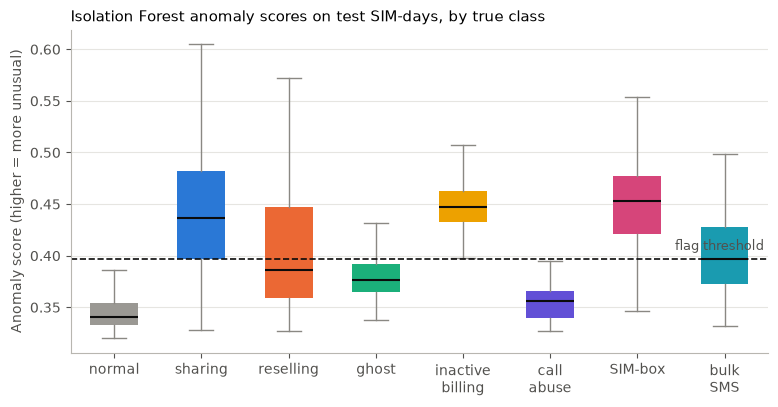

In [25]:
fig, ax = plt.subplots(figsize=(9, 4.2))
data = [iso_score_test[y_test == c] for c in CLASS_ORDER]
bp = ax.boxplot(data, widths=0.55, showfliers=False, patch_artist=True,
                medianprops={"color": "#0b0b0b", "linewidth": 1.5},
                whiskerprops={"color": "#8a8883"}, capprops={"color": "#8a8883"},
                boxprops={"linewidth": 0})
for patch, c in zip(bp["boxes"], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[c])
ax.axhline(iso_threshold, color="#0b0b0b", linewidth=1.2, linestyle="--")
ax.annotate("flag threshold", xy=(len(CLASS_ORDER) + 0.45, iso_threshold), xytext=(0, 4),
            textcoords="offset points", ha="right", va="bottom", fontsize=9, color="#52514e")
ax.set_xticks(range(1, len(CLASS_ORDER) + 1), [SHORT[c] for c in CLASS_ORDER])
ax.set_ylabel("Anomaly score (higher = more unusual)")
ax.set_title("Isolation Forest anomaly scores on test SIM-days, by true class", loc="left")
ax.grid(axis="x", visible=False)
savefig(fig, "iso_scores_by_class.png")
plt.show()

### 5.4 Per SIM: are misuse SIMs caught, and how often do normal SIMs raise false alarms?
An operator reviews SIMs, not single days. A misuse SIM counts as caught if at least one of its misuse days is flagged.

In [26]:
test_frame = pd.DataFrame({"sim": groups[test_idx], "label": y_test, "flag": iso_flag_test})
caught = (test_frame[test_frame.label != "normal"]
          .groupby(["label", "sim"])["flag"].max()
          .groupby("label").agg(["count", "sum"]).reindex(MISUSE))
caught.columns = ["misuse SIMs (test)", "caught (>=1 misuse day flagged)"]
caught["caught (%)"] = (100 * caught.iloc[:, 1] / caught.iloc[:, 0]).round(0)

clean_sims = test_frame.groupby("sim")["label"].apply(lambda s: (s == "normal").all())
clean = test_frame[test_frame.sim.isin(clean_sims[clean_sims].index)]
false_alarm_days = clean.groupby("sim")["flag"].sum()
print(f"{len(false_alarm_days)} test SIMs never misused: "
      f"{(false_alarm_days > 0).mean():.0%} raise at least one false alarm in 90 days; "
      f"median {false_alarm_days.median():.0f} flagged day(s), max {false_alarm_days.max()}")
caught

150 test SIMs never misused: 67% raise at least one false alarm in 90 days; median 1 flagged day(s), max 24


,misuse SIMs (test),caught (>=1 misuse day flagged),caught (%)
label,,,
unauthorized_sharing,31,31,100.0
data_reselling,25,22,88.0
ghost_usage,24,21,88.0
inactive_billing,16,16,100.0
call_abuse,10,2,20.0
sim_box,9,6,67.0
bulk_sms,7,5,71.0


### 5.5 Choosing the alert threshold
The threshold trades missed misuse against false alarms. Flagging a larger share of days catches more misuse but sends operators more false alarms.

In [27]:
rows = []
for share in [0.01, 0.02, 0.055, 0.10, 0.15]:
    thr = np.quantile(iso_score_train, 1 - share)
    flag = (iso_score_test >= thr).astype(int)
    p, r, f, _ = precision_recall_fscore_support(yb_test, flag, average="binary", zero_division=0)
    rows.append({"flag top share of days": f"{share:.1%}", "precision": round(p, 3), "recall": round(r, 3),
                 "f1": round(f, 3), "false alarms per 1,000 normal days": round(1000 * flag[yb_test == 0].mean(), 1)})
pd.DataFrame(rows).set_index("flag top share of days")

,precision,recall,f1,"false alarms per 1,000 normal days"
flag top share of days,,,,
1.0%,0.673,0.110,0.189,3.8
2.0%,0.702,0.212,0.326,6.5
5.5%,0.604,0.534,0.567,25.3
10.0%,0.438,0.678,0.532,62.7
15.0%,0.335,0.780,0.469,111.7


### 5.6 Improving the model: 3-day average + `max_features=0.5`

Sections 5.1–5.5 are the **baseline**. Two changes were chosen by 4-fold cross-validation **within the training
SIMs** (the test set was not used to choose them; chosen on the v2 data and kept unchanged for v3):

- **3-day average:** each day's score becomes the mean of that SIM's scores today and on the previous 2 days
  (past days only, so it still works live). Misuse lasts days (median 5–11), while normal days have one-off spikes,
  so averaging keeps the first and drops the second. Longer windows were tested: 5 days scored about the same, 7 days
  started to delay alerts (inactive-billing recall fell from 95% to 84%), so 3 days is the balance.
- **`max_features=0.5`:** each tree is trained on a random half of the 48 features. Real misuse is unusual on many
  features at once and still stands out in most trees; a quiet normal day is unusual on only a few volume features,
  so half the trees see nothing odd about it.

Also tested and rejected: using only behaviour features (worse), smaller trees (`max_samples=256`, no gain), and
training on normal days only. The last one made inactive-billing recall collapse (95% to 31%), because the billing
gap is always zero on normal days, so the trees never learn to split on it.

From here on, `iso`, `iso_score_test`, `iso_threshold`, `iso_flag_test` and `iso_metrics` refer to the **improved**
model (used in sections 7 and 8); the baseline is kept as `iso_base` / `base`.

In [28]:
SMOOTH_WINDOW = 3     # days averaged per SIM (today + 2 previous days)
MAX_FEATURES = 0.5    # share of features each tree may use

def smooth_scores(scores, idx, window=SMOOTH_WINDOW):
    """Mean of each SIM's score over today and the previous window-1 days (past days only).
    `idx` = positions of these rows in df, used to look up each row's SIM and date."""
    s = pd.DataFrame({"score": scores, "sim": df["sim_id"].to_numpy()[idx],
                      "date": pd.to_datetime(df["date"]).to_numpy()[idx]})
    s = s.sort_values(["sim", "date"])
    s["smoothed"] = s.groupby("sim")["score"].transform(lambda x: x.rolling(window, min_periods=1).mean())
    return s["smoothed"].sort_index().to_numpy()  # back to the original row order

# Keep the baseline for comparison
iso_base = iso
base = {"flag": iso_flag_test, "score": iso_score_test, "threshold": iso_threshold}

iso = IsolationForest(n_estimators=300, max_samples=4096, contamination=contamination,
                      max_features=MAX_FEATURES, random_state=SEED, n_jobs=-1)
t0 = time.time()
iso.fit(X_train[DATA_FEATURES])  # still no labels
print(f"Trained in {time.time() - t0:.1f}s")

iso_score_train = smooth_scores(-iso.score_samples(X_train[DATA_FEATURES]), train_idx)
iso_score_test = smooth_scores(-iso.score_samples(X_test[DATA_FEATURES]), test_idx)
iso_threshold = float(np.quantile(iso_score_train, 1 - contamination))
iso_flag_test = (iso_score_test >= iso_threshold).astype(int)
iso_metrics = binary_metrics(yb_test, iso_flag_test, iso_score_test)
print(f"Threshold: {iso_threshold:.4f} -> flags {iso_flag_test.mean():.2%} of test days")

Trained in 4.2s


Threshold: 0.3913 -> flags 7.55% of test days


#### Baseline vs improved (test SIMs)

In [29]:
def iso_summary(flag, score):
    out = dict(binary_metrics(yb_test, flag, score))
    for c in CLASS_ORDER:
        out[f"days flagged: {SHORT[c].replace(chr(10), ' ')}"] = flag[y_test == c].mean()
    out["days flagged: quiet normal (<50 MB)"] = flag[quiet_normal].mean()
    tf = pd.DataFrame({"sim": groups[test_idx], "label": y_test, "flag": flag})
    for c in MISUSE:
        out[f"SIMs caught: {SHORT[c].replace(chr(10), ' ')}"] = tf[tf.label == c].groupby("sim")["flag"].max().mean()
    never = tf[tf.sim.isin(clean_sims[clean_sims].index)]
    out["never-misused SIMs with >=1 false alarm"] = (never.groupby("sim")["flag"].sum() > 0).mean()
    return out

iso_comparison = pd.DataFrame({"baseline": iso_summary(base["flag"], base["score"]),
                               "improved": iso_summary(iso_flag_test, iso_score_test)})
iso_comparison["change"] = iso_comparison["improved"] - iso_comparison["baseline"]
iso_comparison.round(3)

,baseline,improved,change
precision,0.554,0.584,0.031
recall,0.580,0.656,0.076
f1,0.566,0.618,0.052
roc_auc,0.915,0.942,0.026
pr_auc,0.522,0.611,0.089
days flagged: normal,0.034,0.034,-0.000
days flagged: sharing,0.748,0.823,0.075
days flagged: reselling,0.432,0.712,0.280
days flagged: ghost,0.198,0.282,0.083
days flagged: inactive billing,1.000,0.966,-0.034


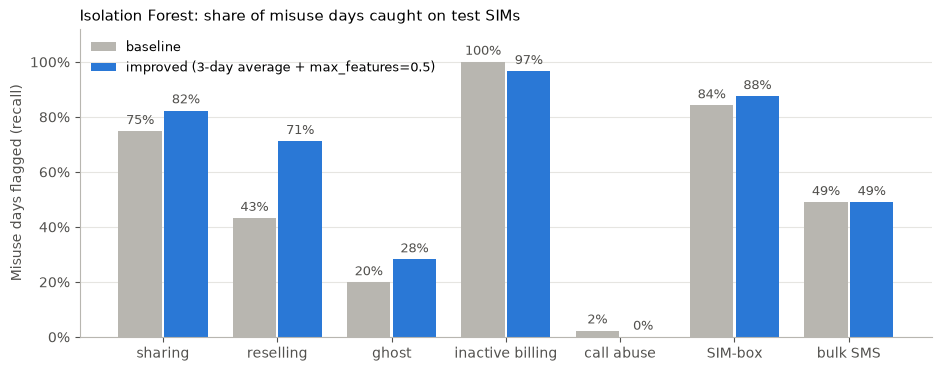

In [30]:
# Share of each misuse type's test days flagged, before and after
from matplotlib.ticker import PercentFormatter

rec_base = [base["flag"][y_test == c].mean() for c in MISUSE]
rec_new = [iso_flag_test[y_test == c].mean() for c in MISUSE]
labels = [SHORT[c].replace("\n", " ") for c in MISUSE]
xpos = np.arange(len(MISUSE))
w = 0.38

fig, ax = plt.subplots(figsize=(11, 4))
b1 = ax.bar(xpos - w / 2 - 0.01, rec_base, w, color="#b8b6b0", label="baseline")
b2 = ax.bar(xpos + w / 2 + 0.01, rec_new, w, color="#2a78d6", label="improved (3-day average + max_features=0.5)")
for bars in (b1, b2):
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in bars.datavalues], padding=3, fontsize=9, color="#52514e")
ax.set_xticks(xpos, labels)
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Misuse days flagged (recall)")
ax.set_title("Isolation Forest: share of misuse days caught on test SIMs", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper left", fontsize=9)
savefig(fig, "iso_baseline_vs_improved.png")
plt.show()

#### Threshold trade-off for the improved model

In [31]:
rows = []
for share in [0.01, 0.02, 0.055, 0.10, 0.15]:
    thr = np.quantile(iso_score_train, 1 - share)
    flag = (iso_score_test >= thr).astype(int)
    p, r, f, _ = precision_recall_fscore_support(yb_test, flag, average="binary", zero_division=0)
    rows.append({"flag top share of days": f"{share:.1%}", "precision": round(p, 3), "recall": round(r, 3),
                 "f1": round(f, 3), "false alarms per 1,000 normal days": round(1000 * flag[yb_test == 0].mean(), 1)})
pd.DataFrame(rows).set_index("flag top share of days")

,precision,recall,f1,"false alarms per 1,000 normal days"
flag top share of days,,,,
1.0%,0.751,0.123,0.211,2.9
2.0%,0.812,0.274,0.409,4.6
5.5%,0.632,0.594,0.612,25.0
10.0%,0.471,0.775,0.586,62.9
15.0%,0.361,0.862,0.509,110.1


### 5.7 Findings

**The improved data forest is better on almost every measure** (251 test SIMs, 48 data features; the two changes were chosen on v2 training SIMs and still help on v3):

| Measure | Baseline | Improved |
|---|---|---|
| Precision | 0.55 | **0.58** |
| Recall | 0.58 | **0.66** |
| F1 | 0.57 | **0.62** |
| ROC-AUC | 0.915 | **0.942** |
| PR-AUC | 0.522 | **0.611** |
| Normal days flagged (false alarms) | 3.4% | 3.4% |
| Quiet normal days (<50 MB) flagged | 4.1% | 4.4% |
| Never-misused SIMs with at least one false alarm in 90 days | 67% | **34%** |

The false-alarm rate per day is unchanged, but false alarms now cluster on fewer SIMs: half as many clean SIMs raise any alert over three months.

**By misuse type** (share of days caught, baseline → improved): sharing 75% → 82%, reselling 43% → 71%, ghost usage 20% → 28%, inactive billing 100% → 97%, SIM-box 84% → 88%, bulk SMS 49% → 49%, **call abuse 2% → 0%**. The data forest sees SIM-box (its data collapses and its session count jumps) and part of bulk SMS (more sessions), but it is blind to call abuse, whose data use does not change. That is the gap the call/SMS forest in 5.8 fills.

**The trade-off: very short episodes.** Averaging over 3 days dilutes one- and two-day episodes, so fewer misuse SIMs have at least one day flagged (for example sharing 100% → 94%, bulk SMS 71% → 57%). For an operator-facing alert a one-day blip is usually not worth an investigation, but this should be stated in the write-up.

**Threshold:** flagging the top 2% of days gives 81% precision and catches 27% of misuse days; flagging 10% catches 78% at 47% precision.

**For deployment (section 8):** the service must apply the same 3-day average, so `SMOOTH_WINDOW = 3` is saved with the model, and scoring a SIM needs its scores for the 2 previous days as well as today.

### 5.8 Call/SMS Isolation Forest
Trained without labels on the call/SMS features only. Each day's score is the **3-day average** of that SIM's scores
(today and the 2 previous days, as for the data forest), and it flags the most unusual **1%** of days, raising its own
alert type, "unusual calling/SMS". Notebook 02 (section 6) chose this setting: compared with daily scoring at 2%, it
gives much cleaner alerts, at the cost of reacting a day or two later. For comparison, daily scoring and the data
forest are shown at the same 1% budget.

In [32]:
CALL_SHARE = 0.01  # the call/SMS forest flags the most unusual 1% of days
call_iso = IsolationForest(n_estimators=300, max_samples=4096, random_state=SEED, n_jobs=-1)
t0 = time.time()
call_iso.fit(X_train[CALL_FEATURES])  # no labels
print(f"Trained in {time.time() - t0:.1f}s on {len(CALL_FEATURES)} call/SMS features")

call_daily_train = -call_iso.score_samples(X_train[CALL_FEATURES])
call_daily_test = -call_iso.score_samples(X_test[CALL_FEATURES])
call_score_train = smooth_scores(call_daily_train, train_idx)  # 3-day average: used from here on
call_score_test = smooth_scores(call_daily_test, test_idx)
call_threshold = float(np.quantile(call_score_train, 1 - CALL_SHARE))
call_flag_test = (call_score_test >= call_threshold).astype(int)
call_daily_flag_test = (call_daily_test >= np.quantile(call_daily_train, 1 - CALL_SHARE)).astype(int)
data_same_budget_flag = (iso_score_test >= np.quantile(iso_score_train, 1 - CALL_SHARE)).astype(int)

is_call = np.isin(y_test, CALL_TYPES)
is_data = np.isin(y_test, DATA_TYPES)
normal_days = y_test == "normal"
keep = is_call | normal_days
lab = pd.Series(y_test)
run = (lab != lab.groupby(groups[test_idx]).shift()).cumsum()
first2 = is_call & ((lab.groupby(run).cumcount() + 1).to_numpy() <= 2)   # first 2 days of each call/SMS episode

DETECTORS = {"data IF (3-day avg, top 1%)": (data_same_budget_flag, iso_score_test),
             "call/SMS IF (3-day avg, top 1%)": (call_flag_test, call_score_test),
             "call/SMS IF (daily, top 1%)": (call_daily_flag_test, call_daily_test)}
rows = {}
for name, (flag, score) in DETECTORS.items():
    r = {"call/SMS misuse days flagged": flag[is_call].mean(),
         "precision (call/SMS misuse vs normal days)": flag[is_call].sum() / max(1, flag[keep].sum()),
         "false alarms per 1,000 normal days": 1000 * flag[normal_days].mean(),
         "first 2 days of call/SMS episodes flagged": flag[first2].mean(),
         "data misuse days flagged": flag[is_data].mean(),
         "PR-AUC (call/SMS misuse vs normal)": average_precision_score(is_call[keep], score[keep])}
    for c in MISUSE:
        r[f"days flagged: {SHORT[c].replace(chr(10), ' ')}"] = flag[y_test == c].mean()
    tf_c = pd.DataFrame({"sim": groups[test_idx], "label": y_test, "flag": flag})
    for c in CALL_TYPES:
        r[f"SIMs caught: {SHORT[c].replace(chr(10), ' ')}"] = tf_c[tf_c.label == c].groupby("sim")["flag"].max().mean()
    rows[name] = r
call_table = pd.DataFrame(rows)
print("Test SIMs per call type:", {c: int(pd.Series(groups[test_idx][y_test == c]).nunique()) for c in CALL_TYPES})
call_table.round(3)

Trained in 1.5s on 20 call/SMS features


Test SIMs per call type: {'call_abuse': 10, 'sim_box': 9, 'bulk_sms': 7}


,"data IF (3-day avg, top 1%)","call/SMS IF (3-day avg, top 1%)","call/SMS IF (daily, top 1%)"
call/SMS misuse days flagged,0.117,0.703,0.613
precision (call/SMS misuse vs normal days),0.326,0.700,0.595
"false alarms per 1,000 normal days",2.943,3.654,5.078
first 2 days of call/SMS episodes flagged,0.041,0.306,0.653
data misuse days flagged,0.124,0.001,0.003
PR-AUC (call/SMS misuse vs normal),0.200,0.760,0.668
days flagged: sharing,0.231,0.003,0.005
days flagged: reselling,0.186,0.000,0.000
days flagged: ghost,0.003,0.000,0.003
days flagged: inactive billing,0.078,0.000,0.003


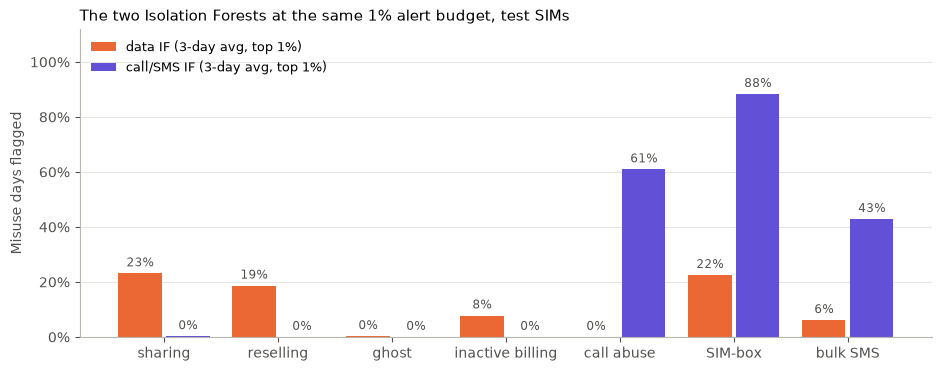

In [33]:
from matplotlib.ticker import PercentFormatter

SHOW = {"data IF (3-day avg, top 1%)": "#eb6834", "call/SMS IF (3-day avg, top 1%)": "#6250d6"}
xpos = np.arange(len(MISUSE))
fig, ax = plt.subplots(figsize=(11, 4))
for k, (name, color) in enumerate(SHOW.items()):
    vals = [call_table.loc[f"days flagged: {SHORT[c].replace(chr(10), ' ')}", name] for c in MISUSE]
    bars = ax.bar(xpos + (k - 0.5) * 0.4 + (0.01 if k else -0.01), vals, 0.38, color=color, label=name)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals], padding=3, fontsize=8.5, color="#52514e")
ax.set_xticks(xpos, [SHORT[c].replace("\n", " ") for c in MISUSE])
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Misuse days flagged")
ax.set_title("The two Isolation Forests at the same 1% alert budget, test SIMs", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper left", fontsize=9)
savefig(fig, "call_sms_if_by_type.png")
plt.show()

### 5.9 Findings: call/SMS Isolation Forest

**Setting used: 3-day average, top 1% of days** (chosen in notebook 02, section 6, by cross-validation on training SIMs).

**It catches the call/SMS misuse the data forest misses** (test SIMs, all at a 1% alert budget):

| Detector | Call/SMS misuse days caught | Precision | False alarms per 1,000 normal days | First 2 days of an episode caught | PR-AUC (call/SMS misuse vs normal) |
|---|---|---|---|---|---|
| Data IF (3-day average) | 12% | 33% | 2.9 | 4% | 0.20 |
| **Call/SMS IF (3-day average)** | **70%** | **70%** | 3.7 | 31% | **0.76** |
| Call/SMS IF (daily) | 61% | 59% | 5.1 | **65%** | 0.67 |

**By type** (days caught): SIM-box 88%, call abuse 61%, bulk SMS 43%. At least one misuse day is flagged on 8 of 10 call-abuse SIMs, 7 of 9 SIM-box SIMs and 4 of 7 bulk-SMS SIMs. It flags almost no data-misuse days (0.1%), so it covers different misuse from the data forest.

**What the 3-day average gives and costs, compared with daily scoring at the same budget:** 9 points more misuse days caught (70% vs 61%), 11 points more precision (70% vs 59%), and a quarter fewer false alarms. But it reacts more slowly: only 31% of the first two days of an episode are flagged, against 65% for daily scoring, so alerts usually arrive on the second or third day. Short bulk-SMS bursts (median episode 4 days) are the type most affected.

**Remaining false alarms come mostly from legitimate heavy callers and SIMs that call abroad** (notebook 02, sections 4 and 6). Comparing each SIM with its own past was tried and made the model worse overall (notebook 02, section 6.4).

## 6. Random Forest  (issue #6)

- [x] Multiclass, `class_weight='balanced_subsample'`, 400 trees, `n_jobs=-1`
- [x] Tune `max_depth` / `min_samples_leaf` with `GroupKFold` on the training SIMs
- [x] Classification report per class + confusion matrix (saved to `reports/`)

Unlike the Isolation Forest, the Random Forest **learns from the labels**: it is shown thousands of SIM-days
marked normal or one of the seven misuse types, and learns which feature patterns go with each. It uses all
features: the 48 data and billing features and the call/SMS features. It therefore says not only *that* a day is suspicious but *which* misuse it looks like.

`class_weight='balanced_subsample'` makes each tree treat the rare misuse days as seriously as the 93% normal
days; without it the forest could score 93% accuracy by calling everything normal.

### 6.1 Tune on the training SIMs (group cross-validation)
Each setting is trained on 3/4 of the training SIMs and scored on the other 1/4, four times. The test SIMs are not used. Score = macro F1 (the average F1 over the eight classes, so rare types count as much as normal days).

In [34]:
from itertools import product
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import GroupKFold

GRID = {"max_depth": [None, 20], "min_samples_leaf": [1, 2, 5]}
gkf = GroupKFold(n_splits=4)
results = []
t0 = time.time()
for max_depth, min_leaf in product(GRID["max_depth"], GRID["min_samples_leaf"]):
    fold_scores = []
    for fit_i, val_i in gkf.split(X_train, y_train, groups_train):
        m = RandomForestClassifier(n_estimators=200, max_depth=max_depth, min_samples_leaf=min_leaf,
                                   class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)
        m.fit(X_train.iloc[fit_i], y_train[fit_i])
        fold_scores.append(f1_score(y_train[val_i], m.predict(X_train.iloc[val_i]), average="macro"))
    results.append({"max_depth": "none" if max_depth is None else max_depth, "min_samples_leaf": min_leaf,
                    "macro F1 (mean)": np.mean(fold_scores), "macro F1 (std)": np.std(fold_scores)})
tuning = pd.DataFrame(results).sort_values("macro F1 (mean)", ascending=False).reset_index(drop=True)
best = tuning.iloc[0]
RF_PARAMS = {"max_depth": None if best["max_depth"] == "none" else int(best["max_depth"]),
             "min_samples_leaf": int(best["min_samples_leaf"])}
print(f"Tuning took {time.time() - t0:.0f}s | best: {RF_PARAMS}")
tuning.round(4)

Tuning took 350s | best: {'max_depth': None, 'min_samples_leaf': 5}


,max_depth,min_samples_leaf,macro F1 (mean),macro F1 (std)
0,none,5,0.8751,0.0300
1,20,5,0.8666,0.0194
2,none,2,0.8657,0.0332
3,20,2,0.8548,0.0319
4,20,1,0.8474,0.0328
5,none,1,0.8470,0.0379


### 6.2 Train the final model on all training SIMs

In [35]:
rf = RandomForestClassifier(n_estimators=400, **RF_PARAMS, class_weight="balanced_subsample",
                            random_state=SEED, n_jobs=-1)
t0 = time.time()
rf.fit(X_train, y_train)
print(f"Trained in {time.time() - t0:.1f}s on {len(X_train):,} SIM-days")

rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)
RF_CLASSES = list(rf.classes_)
rf_misuse_score = 1 - rf_proba[:, RF_CLASSES.index("normal")]   # probability of any misuse
rf_flag_test = (rf_pred != "normal").astype(int)

Trained in 39.2s on 67,410 SIM-days


### 6.3 Per class (test SIMs)

In [36]:
rf_report = classification_report(y_test, rf_pred, output_dict=True, zero_division=0)
per_class = (pd.DataFrame(rf_report).T.loc[CLASS_ORDER, ["precision", "recall", "f1-score", "support"]]
             .rename(columns={"support": "test days"}))
per_class["test days"] = per_class["test days"].astype(int)
print(f"Macro F1: {rf_report['macro avg']['f1-score']:.3f} | accuracy: {rf_report['accuracy']:.3f} "
      f"(accuracy is misleading here: calling every day normal would score {np.mean(y_test == 'normal'):.3f})")
per_class.round(3)

Macro F1: 0.864 | accuracy: 0.981 (accuracy is misleading here: calling every day normal would score 0.933)


,precision,recall,f1-score,test days
normal,0.989,0.992,0.990,21070
unauthorized_sharing,0.746,0.792,0.768,385
data_reselling,0.841,0.492,0.620,236
ghost_usage,0.856,0.957,0.904,348
inactive_billing,1.000,1.000,1.000,295
call_abuse,0.852,0.529,0.652,87
sim_box,1.000,1.000,1.000,120
bulk_sms,1.000,0.959,0.979,49


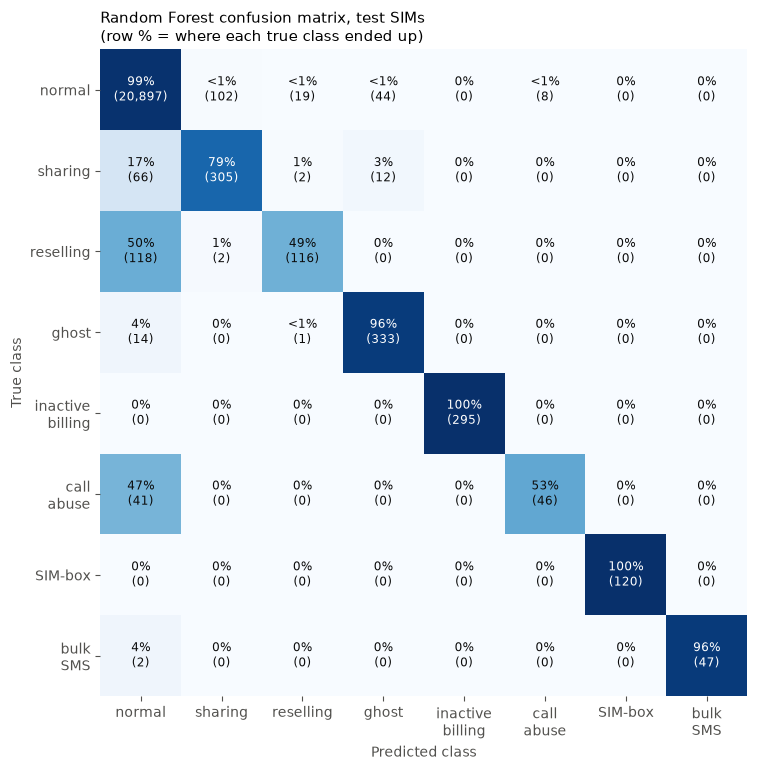

In [37]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf_pred, labels=CLASS_ORDER)
cm_pct = cm / cm.sum(axis=1, keepdims=True)  # each row sums to 100%: where that true class ended up
names = [SHORT[c] for c in CLASS_ORDER]

fig, ax = plt.subplots(figsize=(10, 8.4))
ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASS_ORDER)):
    for j in range(len(CLASS_ORDER)):
        dark = cm_pct[i, j] > 0.55
        pct = "<1%" if 0 < cm_pct[i, j] < 0.005 else f"{cm_pct[i, j]:.0%}"
        ax.text(j, i, f"{pct}\n({cm[i, j]:,})", ha="center", va="center", fontsize=8.5,
                color="#ffffff" if dark else "#0b0b0b")
ax.set_xticks(range(len(names)), names)
ax.set_yticks(range(len(names)), names)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Random Forest confusion matrix, test SIMs\n(row % = where each true class ended up)", loc="left")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
savefig(fig, "rf_confusion_matrix.png")
plt.show()

### 6.4 Misuse vs normal, and per SIM
The same views as the Isolation Forest (section 5), so the two can be compared in section 7.

In [38]:
rf_metrics = binary_metrics(yb_test, rf_flag_test, rf_misuse_score)
print(f"Normal days flagged (false alarms): {rf_flag_test[yb_test == 0].mean():.2%}")
print(f"Quiet normal days (<50 MB) flagged: {rf_flag_test[quiet_normal].mean():.1%} of {quiet_normal.sum()}")

tf = pd.DataFrame({"sim": groups[test_idx], "label": y_test, "flag": rf_flag_test, "pred": rf_pred})
caught = tf[tf.label != "normal"].groupby(["label", "sim"]).apply(
    lambda d: (d["pred"] != "normal").any(), include_groups=False).groupby("label").agg(["count", "sum"]).reindex(MISUSE)
caught.columns = ["misuse SIMs (test)", "caught (>=1 misuse day flagged)"]
caught["caught (%)"] = (100 * caught.iloc[:, 1] / caught.iloc[:, 0]).round(0)
never = tf[tf.sim.isin(clean_sims[clean_sims].index)]
fa = never.groupby("sim")["flag"].sum()
print(f"Never-misused test SIMs with >=1 false alarm in 90 days: {(fa > 0).mean():.0%} of {len(fa)}")
display(pd.Series(rf_metrics, name="Random Forest").to_frame().T)
caught

Normal days flagged (false alarms): 0.82%
Quiet normal days (<50 MB) flagged: 10.5% of 342
Never-misused test SIMs with >=1 false alarm in 90 days: 37% of 150


,precision,recall,f1,roc_auc,pr_auc
Random Forest,0.8809,0.8414,0.8607,0.9821,0.9198


,misuse SIMs (test),caught (>=1 misuse day flagged),caught (%)
label,,,
unauthorized_sharing,31,29,94.0
data_reselling,25,21,84.0
ghost_usage,24,24,100.0
inactive_billing,16,16,100.0
call_abuse,10,9,90.0
sim_box,9,9,100.0
bulk_sms,7,7,100.0


### 6.5 Findings

**Tuning:** the best setting was `max_depth=None`, `min_samples_leaf=5` (macro F1 0.875 ± 0.030 across the four training folds; v2's best was depth 20, leaf 2). All six settings scored between 0.847 and 0.875, so the forest is not very sensitive to them; requiring at least 5 days per leaf stops it from memorising individual SIM-days.

**Misuse vs normal (251 test SIMs):** precision 0.88, recall 0.84, F1 0.86, ROC-AUC 0.982, PR-AUC 0.920. Accuracy (98.1%) is not a useful measure: calling every day normal would already score 93.3%.

**By misuse type:**

| Type | Precision | Recall | F1 | Reading |
|---|---|---|---|---|
| Inactive billing | 1.00 | 1.00 | 1.00 | Perfect, as expected: the billing gap separates it exactly (section 2.6) |
| SIM-box | 1.00 | 1.00 | 1.00 | Dozens of calls to new numbers while data collapses: very distinctive |
| Bulk SMS | 1.00 | 0.96 | 0.98 | Many SMS to new numbers |
| Ghost usage | 0.86 | 0.96 | 0.90 | Learns the off-peak pattern that separates it from quiet normal days |
| Unauthorized sharing | 0.75 | 0.79 | 0.77 | 17% of its days are called normal |
| Call abuse | 0.85 | 0.53 | 0.65 | 47% of its days are called normal |
| Data reselling | 0.84 | 0.49 | 0.62 | Weakest: 50% of its days are called normal |

**The types are almost never confused with each other.** Apart from 12 sharing days called ghost usage, nearly every mistake is misuse vs normal, so the type the forest names can be trusted.

**Two weak types, both for the same reason: the change is small for some episodes.** Reselling barely changes volume (section 3.3). Call abuse is drawn per episode from "barely above normal" to obvious, and its milder episodes (a few extra long calls to the SIM's usual contacts) look like a normal SIM having a long phone day. Without labels, the call/SMS forest flags 61% of call-abuse days (5.8), more than the forest's 53%, and it catches 19 call-abuse days the forest missed (7.4), which is the main reason to run it alongside.

**False alarms:** 0.82% of normal days are flagged (173 of 21,070), a quarter of the data forest's rate. Quiet normal days (under 50 MB) are flagged 10.5% of the time, still the hardest normal case. 37% of never-misused test SIMs raise at least one false alarm over 90 days.

**Per SIM:** at least one misuse day is caught on 94% of sharing SIMs, 84% of reselling, 90% of call abuse, and 100% of ghost-usage, inactive-billing, SIM-box and bulk-SMS SIMs.

**For the write-up:** the supervised forest is clearly the strongest model wherever labelled examples exist, and it names the type. Its limits are that it needs labels, recognises only the seven types it was trained on, and its perfect inactive-billing and SIM-box scores reflect how the synthetic data was generated more than real-world difficulty.

## 7. Compare models  (issue #7)

- [x] Comparison table: data Isolation Forest (baseline and improved), call/SMS Isolation Forest, Random Forest
- [x] Precision-recall curves and feature importance chart (saved to `reports/`)
- [x] Combined design: Random Forest as main detector, both Isolation Forests as safety nets
- [x] Unseen-misuse test: can the safety nets catch a type the Random Forest was never taught?
- [x] Notes for the write-up: inactive-billing separability, data-reselling weakness

All numbers are on the 251 test SIMs, which no model or setting was tuned on.

### 7.1 Side by side

In [39]:
comparison = pd.DataFrame({
    "IF baseline": iso_summary(base["flag"], base["score"]),
    "IF improved": iso_summary(iso_flag_test, iso_score_test),
    "call/SMS IF (3-day avg)": iso_summary(call_flag_test, call_score_test),
    "Random Forest": iso_summary(rf_flag_test, rf_misuse_score),
})
comparison.round(3)

,IF baseline,IF improved,call/SMS IF (3-day avg),Random Forest
precision,0.554,0.584,0.702,0.881
recall,0.580,0.656,0.119,0.841
f1,0.566,0.618,0.204,0.861
roc_auc,0.915,0.942,0.444,0.982
pr_auc,0.522,0.611,0.184,0.920
days flagged: normal,0.034,0.034,0.004,0.008
days flagged: sharing,0.748,0.823,0.003,0.829
days flagged: reselling,0.432,0.712,0.000,0.500
days flagged: ghost,0.198,0.282,0.000,0.960
days flagged: inactive billing,1.000,0.966,0.000,1.000


### 7.2 Precision-recall curves
Each curve shows every possible alert threshold: further up and to the right is better. Dots mark the threshold each model actually uses. With misuse on only ~5% of days, this is a fairer picture than ROC curves, which look good even for weak models when normal days dominate.

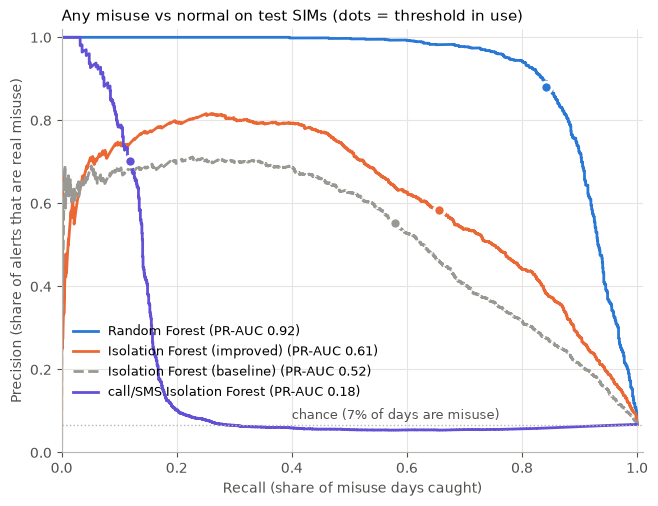

In [40]:
from sklearn.metrics import precision_recall_curve

CURVES = [("Random Forest", rf_misuse_score, rf_flag_test, "#2a78d6", "-"),
          ("Isolation Forest (improved)", iso_score_test, iso_flag_test, "#eb6834", "-"),
          ("Isolation Forest (baseline)", base["score"], base["flag"], "#9a9893", "--"),
          ("call/SMS Isolation Forest", call_score_test, call_flag_test, "#6250d6", "-")]

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for name, score, flag, color, ls in CURVES:
    p, r, _ = precision_recall_curve(yb_test, score)
    ax.plot(r, p, color=color, linewidth=2, linestyle=ls,
            label=f"{name} (PR-AUC {average_precision_score(yb_test, score):.2f})")
    op_p, op_r, _, _ = precision_recall_fscore_support(yb_test, flag, average="binary", zero_division=0)
    ax.plot(op_r, op_p, "o", color=color, markersize=8, markeredgecolor="#ffffff", markeredgewidth=2)
ax.axhline(yb_test.mean(), color="#b8b6b0", linewidth=1, linestyle=":")
ax.annotate(f"chance ({yb_test.mean():.0%} of days are misuse)", xy=(0.40, yb_test.mean()), xytext=(0, 4),
            textcoords="offset points", fontsize=9, color="#52514e")
ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall (share of misuse days caught)")
ax.set_ylabel("Precision (share of alerts that are real misuse)")
ax.set_title("Any misuse vs normal on test SIMs (dots = threshold in use)", loc="left")
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.0, 0.10), fontsize=9)
savefig(fig, "pr_curves.png")
plt.show()

### 7.3 What the Random Forest relies on
Importance = how much each feature reduces impurity across all trees (mean decrease in impurity). It shows what the forest uses, though it can spread credit across correlated features, so the totals per feature group are the more robust view.

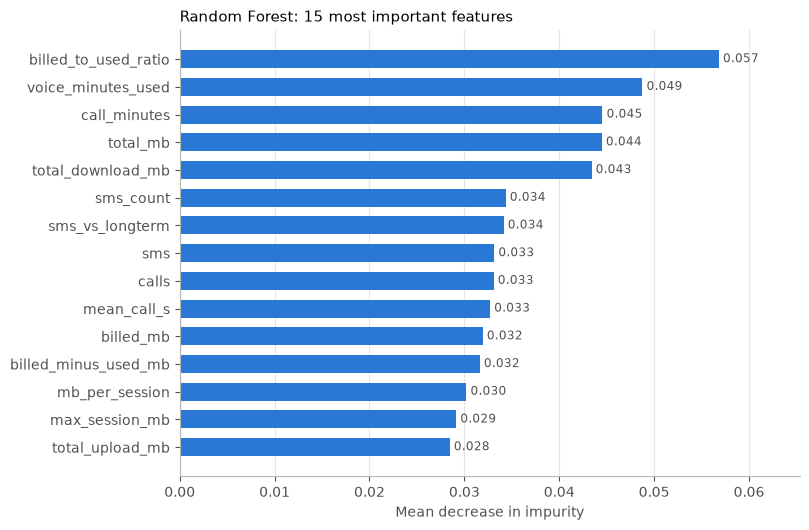

,total importance,features
raw daily usage,0.360,17
calls and SMS,0.284,20
vs own 14-day baseline,0.094,14
vs own long-term baseline,0.093,7
billing gap,0.088,2
usage-pattern ratios,0.078,5
tier,0.002,3


In [41]:
RATIO_COLS = ["upload_share", "offpeak_share", "hotspot_share", "public_apn_share", "mb_per_session"]
BILLING_COLS = ["billed_minus_used_mb", "billed_to_used_ratio"]

def feature_group(f):
    if f in CALL_FEATURES: return "calls and SMS"
    if f in RAW_COLS: return "raw daily usage"
    if f in RATIO_COLS: return "usage-pattern ratios"
    if f in BILLING_COLS: return "billing gap"
    if f.endswith("_vs_longterm"): return "vs own long-term baseline"
    if f.endswith(("_vs_baseline", "_z")): return "vs own 14-day baseline"
    if f.startswith("tier_"): return "tier"
    raise ValueError(f)

importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)
group_importance = (importance.groupby(importance.index.map(feature_group)).agg(["sum", "count"])
                    .sort_values("sum", ascending=False)
                    .rename(columns={"sum": "total importance", "count": "features"}))

top = importance.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.8))
bars = ax.barh(top.index, top.values, color="#2a78d6", height=0.65)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in top.values], padding=3, fontsize=8.5, color="#52514e")
ax.set_xlabel("Mean decrease in impurity")
ax.set_title("Random Forest: 15 most important features", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, top.max() * 1.15)
savefig(fig, "rf_feature_importance.png")
plt.show()
group_importance.round(3)

### 7.4 Combined design: Random Forest + two Isolation Forest safety nets

| Random Forest | Data IF (3-day average) | Call/SMS IF (3-day average) | Alert level |
|---|---|---|---|
| misuse | unusual (normal threshold, ~6.7% of days) | any | **High**: misuse, with type, confirmed by the data forest |
| misuse | not unusual | any | **Alert**: misuse, with type |
| normal | unusual at a **strict** threshold (top 2%) | any | **Review**: unusual data use, unclassified |
| normal | not that unusual | unusual (top 1%) | **Review (calls/SMS)**: unusual calling or texting |
| normal | not that unusual | not unusual | none |

The strict thresholds keep the extra review alerts few.

In [42]:
SAFETY_SHARE = 0.02  # the safety net flags only the most unusual 2% of days
iso_strict = float(np.quantile(iso_score_train, 1 - SAFETY_SHARE))
iso_strict_flag = (iso_score_test >= iso_strict).astype(int)

rf_alert = rf_flag_test == 1
alert_level = np.select(
    [rf_alert & (iso_flag_test == 1), rf_alert, ~rf_alert & (iso_strict_flag == 1),
     ~rf_alert & (call_flag_test == 1)],
    ["High", "Alert", "Review", "Review (calls/SMS)"], default="none")

levels = ["High", "Alert", "Review", "Review (calls/SMS)"]
tier = pd.DataFrame({
    "test days": pd.Series(alert_level).value_counts().reindex(levels),
    "real misuse (%)": (100 * pd.Series(yb_test).groupby(alert_level).mean()).reindex(levels).round(1),
})
for c in MISUSE:
    tier[f"{SHORT[c].replace(chr(10), ' ')} days"] = pd.Series(y_test == c).groupby(alert_level).sum().reindex(levels)
tier["normal days"] = pd.Series(y_test == "normal").groupby(alert_level).sum().reindex(levels)
tier

,test days,real misuse (%),sharing days,reselling days,ghost days,inactive billing days,call abuse days,SIM-box days,bulk SMS days,normal days
High,949,94.5,281,109,93,285,0,105,24,52
Alert,503,75.9,38,9,241,10,46,15,23,121
Review,112,21.4,7,17,0,0,0,0,0,88
Review (calls/SMS),91,20.9,0,0,0,0,19,0,0,72


In [43]:
combined_flag = (alert_level != "none").astype(int)
def alerts_only(flag):
    s = iso_summary(flag, rf_misuse_score)
    return {k: v for k, v in s.items() if k not in ("roc_auc", "pr_auc")}  # AUC needs a score, not a rule

combined = pd.DataFrame({"Random Forest alone": alerts_only(rf_flag_test),
                         "Random Forest + safety net": alerts_only(combined_flag)})
combined["change"] = combined.iloc[:, 1] - combined.iloc[:, 0]
combined.round(3)

,Random Forest alone,Random Forest + safety net,change
precision,0.881,0.799,-0.082
recall,0.841,0.870,0.028
f1,0.861,0.833,-0.028
days flagged: normal,0.008,0.016,0.008
days flagged: sharing,0.829,0.847,0.018
days flagged: reselling,0.500,0.572,0.072
days flagged: ghost,0.960,0.960,0.000
days flagged: inactive billing,1.000,1.000,0.000
days flagged: call abuse,0.529,0.747,0.218
days flagged: SIM-box,1.000,1.000,0.000


How strict should the data safety net be? Extra misuse days it catches that the Random Forest missed, against the extra false alarms it adds:

In [44]:
rows = []
missed_by_rf = (yb_test == 1) & ~rf_alert
for share in [0.01, 0.02, 0.05]:
    flag = iso_score_test >= np.quantile(iso_score_train, 1 - share)
    extra = flag & ~rf_alert
    rows.append({"safety net flags top": f"{share:.0%}",
                 "misuse days RF missed": int(missed_by_rf.sum()),
                 "of those, caught by safety net": int((extra & (yb_test == 1)).sum()),
                 "extra false alarms": int((extra & (yb_test == 0)).sum()),
                 "extra false alarms per 1,000 normal days": round(1000 * (extra & (yb_test == 0)).sum() / (yb_test == 0).sum(), 1)})
pd.DataFrame(rows).set_index("safety net flags top")

,misuse days RF missed,"of those, caught by safety net",extra false alarms,"extra false alarms per 1,000 normal days"
safety net flags top,,,,
1%,241,11,55,2.6
2%,241,24,88,4.2
5%,241,77,409,19.4


And the call/SMS safety net, daily and as a 3-day average. "Flagged if never labelled" is the share of call/SMS misuse days it flags on its own, which is what it would still catch for a type the Random Forest had never been taught. "Extra" alerts are those raised only by this net (the Random Forest and the data net both said nothing).

In [45]:
rows = []
for version, tr_s, te_s in [("daily", call_daily_train, call_daily_test), ("3-day average", call_score_train, call_score_test)]:
    for share in [0.005, 0.01, 0.02]:
        flag = te_s >= np.quantile(tr_s, 1 - share)
        extra = flag & ~rf_alert & (iso_strict_flag == 0)
        rows.append({"call/SMS IF": version, "flags top": f"{share:.1%}",
                     "call/SMS misuse days flagged (if never labelled)": round(flag[is_call].mean(), 3),
                     "call/SMS days RF missed, caught": int((extra & is_call).sum()),
                     "extra false alarms per 1,000 normal days": round(1000 * (extra & (yb_test == 0)).sum() / (yb_test == 0).sum(), 1),
                     "real misuse among its extra alerts": round(yb_test[extra].mean(), 3) if extra.any() else np.nan})
print(f"Call/SMS misuse days the Random Forest missed: {int((is_call & ~rf_alert).sum())} of {int(is_call.sum())}")
pd.DataFrame(rows).set_index(["call/SMS IF", "flags top"])

Call/SMS misuse days the Random Forest missed: 43 of 256


call/SMS misuse days flagged (if never labelled)  \
call/SMS IF   flags top                                                     
daily         0.5%                                                  0.340   
              1.0%                                                  0.613   
              2.0%                                                  0.816   
3-day average 0.5%                                                  0.324   
              1.0%                                                  0.703   
              2.0%                                                  0.859   

                         call/SMS days RF missed, caught  \
call/SMS IF   flags top                                    
daily         0.5%                                     2   
              1.0%                                     5   
              2.0%                                    17   
3-day average 0.5%                                     3   
              1.0%                                    19   
              2.0%                                    29   

                         extra false alarms per 1,000 normal days  \
call/SMS IF   flags top                                             
daily         0.5%                                            0.5   
              1.0%                                            4.7   
              2.0%                                           15.1   
3-day average 0.5%                                            0.2   
              1.0%                                            3.4   
              2.0%                                           14.0   

                         real misuse among its extra alerts  
call/SMS IF   flags top                                      
daily         0.5%                                    0.154  
              1.0%                                    0.048  
              2.0%                                    0.051  
3-day average 0.5%                                    0.429  
              1.0%                                    0.209  
              2.0%                                    0.089

### 7.5 Unseen misuse: what if a type had never been labelled?

The Random Forest can only recognise misuse it was taught. To test the safety net's real purpose, each misuse type
in turn is **hidden** from the Random Forest: its training days are relabelled `normal`, exactly as an
undiscovered fraud would sit unlabelled in real data. Both Isolation Forests are unchanged (they never used labels).
Then: what share of that type's test days does each approach still flag?

In [46]:
rows = []
t0 = time.time()
for hidden in MISUSE:
    y_hidden = np.where(y_train == hidden, "normal", y_train)
    rf_h = RandomForestClassifier(n_estimators=200, **RF_PARAMS, class_weight="balanced_subsample",
                                  random_state=SEED, n_jobs=-1).fit(X_train, y_hidden)
    rf_h_flag = rf_h.predict(X_test) != "normal"
    is_t = y_test == hidden
    rows.append({"hidden type": SHORT[hidden].replace(chr(10), " "),
                 "RF (never taught it)": rf_h_flag[is_t].mean(),
                 "data IF alone (top 2%)": iso_strict_flag[is_t].mean().astype(float),
                 "call/SMS IF alone (3-day avg, top 1%)": call_flag_test[is_t].mean().astype(float),
                 "RF + both safety nets": (rf_h_flag | (iso_strict_flag == 1) | (call_flag_test == 1))[is_t].mean(),
                 "RF when taught (6.3)": rf_flag_test[is_t].mean()})
print(f"{len(MISUSE)} models trained in {time.time() - t0:.0f}s")
unseen = pd.DataFrame(rows).set_index("hidden type")
(100 * unseen).round(1).astype(str) + "%"

7 models trained in 151s


,RF (never taught it),data IF alone (top 2%),"call/SMS IF alone (3-day avg, top 1%)",RF + both safety nets,RF when taught (6.3)
hidden type,,,,,
sharing,4.7%,35.1%,0.3%,36.4%,82.9%
reselling,1.3%,33.5%,0.0%,33.9%,50.0%
ghost,0.0%,0.9%,0.0%,0.9%,96.0%
inactive billing,0.0%,41.4%,0.0%,41.4%,100.0%
call abuse,0.0%,0.0%,60.9%,60.9%,52.9%
SIM-box,0.0%,59.2%,88.3%,88.3%,100.0%
bulk SMS,0.0%,12.2%,42.9%,42.9%,95.9%


### 7.6 Findings

**The Random Forest is the strongest model wherever labels exist.** On any misuse vs normal it reaches precision 0.88 and recall 0.84 (PR-AUC 0.92), against 0.58 and 0.66 (PR-AUC 0.61) for the improved data forest, with a quarter of the false-alarm rate (0.8% vs 3.4% of normal days). The call/SMS forest scores low on this overall measure (recall 0.12, PR-AUC 0.18) only because it is meant to ignore data misuse, which is most of the misuse days; on call/SMS misuse alone it reaches 70% recall at 70% precision (section 5.9).

**What the Random Forest relies on** (share of total importance):

| Feature group | Features | Importance |
|---|---|---|
| Raw daily usage | 17 | 36% |
| Calls and SMS (new) | 20 | 28% |
| Change vs own 14-day baseline | 14 | 9% |
| Change vs own long-term baseline | 7 | 9% |
| Billing gap | 2 | 9% |
| Usage-pattern ratios | 5 | 8% |
| Tier | 3 | 0.2% |

The new call/SMS features are the second most important group, and five of them are in the top 15 (call minutes, SMS vs long-term, SMS, calls, mean call length). The single most important feature is still the billed-to-used ratio. Tier contributes almost nothing and could be dropped.

**Combined design, on the known misuse types:**

| Alert level | Test days | Real misuse |
|---|---|---|
| High (Random Forest + data forest agree) | 949 | 94.5% |
| Alert (Random Forest only) | 503 | 75.9% |
| Review (data forest only, top 2%) | 112 | 21.4% |
| Review (calls/SMS) (call/SMS forest only, 3-day average, top 1%) | 91 | 20.9% |

Adding both safety nets raises recall from 0.84 to 0.87 and lowers precision from 0.88 to 0.80. The share of clean SIMs with at least one false alarm rises from 37% to 44%. The two review queues are now about the same size and quality: about 1 alert in 5 is real misuse.

**Switching the call/SMS net from daily at 2% to a 3-day average at 1%** (the setting chosen in notebook 02) cut its review queue from 336 to 91 alerts. The share that is real misuse rose from 5% to 21%, the combined precision went from 0.70 to 0.80, and clean SIMs with a false alarm went from 57% to 44%. It still catches 19 call-abuse days the Random Forest missed. The cost is speed and some coverage of unlabelled types (below). The second table in section 7.4 shows the other options.

**The safety nets' real value is misuse nobody has labelled yet.** With one type hidden from the Random Forest (relabelled normal, as undiscovered fraud would be):

| Hidden type | Random Forest (never taught it) | Data forest (top 2%) | Call/SMS forest (3-day average, top 1%) |
|---|---|---|---|
| Unauthorized sharing | 4.7% | 35.1% | 0.3% |
| Data reselling | 1.3% | 33.5% | 0.0% |
| Inactive billing | 0.0% | 41.4% | 0.0% |
| Ghost usage | 0.0% | 0.9% | 0.0% |
| Call abuse | 0.0% | 0.0% | 60.9% |
| SIM-box | 0.0% | 59.2% | 88.3% |
| Bulk SMS | 0.0% | 12.2% | 42.9% |

A Random Forest that was never shown a type is blind to it. Between them the two forests still flag a third or more of the days of every type except ghost usage, and each covers what the other misses. Compared with daily scoring at 2%, the stricter call/SMS setting catches less of an unlabelled type (call abuse 61% vs 68%, SIM-box 88% vs 98%, bulk SMS 43% vs 67%), the price of a review queue operators can trust. Ghost usage stays the exception: unlabelled, it looks like a quiet normal period to every model.

**Recommendation for the portal:** the combined design with three models. Operators work through High alerts first (almost always real), then Alerts (named type, about 3 in 4 real). The two Review queues (about 1 in 5 real) exist to surface new kinds of misuse.

**Notes for the write-up:**
- **Inactive billing and SIM-box score perfectly** in the Random Forest because the synthetic data makes them very distinctive. Real data would be harder.
- **Data reselling and call abuse are the weakest types** (Random Forest recall 49% and 53%), both because some episodes change behaviour only slightly.
- **The call/SMS net reacts a day or two late** (31% of episodes' first 2 days flagged); if fast response to SIM-box matters more than a clean queue, daily scoring at 1% is the alternative (65% of first days, at lower precision).
- **The test set is small for the call types** (7-10 SIMs each), so per-type figures carry real uncertainty.
- **All results are on synthetic data.** The method (features from each SIM's own history, split by SIM, no tuning on the test set) transfers to real CDRs; the numbers will not.

## 8. Save models and metadata  (issue #8)

- [x] Refit all three models on ALL SIMs; save with `joblib` to `MODELS_DIR` (`ml-service/models`, gitignored)
- [x] Save metadata JSON: feature lists in order, thresholds, smoothing, class names, alert rules, library versions
- [x] Reload the saved files and check they give the same results
- [x] Save metrics JSON to `REPORTS_DIR`

**Why refit on all SIMs:** sections 5-7 held back 251 SIMs to measure honestly how well each model works. Now that the
settings are fixed, the final models are trained on all 1,000 SIMs, so they learn from a third more misuse examples.
The thresholds are recomputed the same way (same alert budgets) on all SIMs. The test results in sections 5-7 remain
the performance estimate: the refitted models have no held-out data of their own.

### 8.1 Refit on all SIMs

In [47]:
import datetime
import json
import platform

all_idx = np.arange(len(df))
contamination_all = float(y_bin.mean())
t0 = time.time()
final_rf = RandomForestClassifier(n_estimators=400, **RF_PARAMS, class_weight="balanced_subsample",
                                  random_state=SEED, n_jobs=-1).fit(X[FEATURES], y)
final_data_iso = IsolationForest(n_estimators=300, max_samples=4096, contamination=contamination_all,
                                 max_features=MAX_FEATURES, random_state=SEED, n_jobs=-1).fit(X[DATA_FEATURES])
final_call_iso = IsolationForest(n_estimators=300, max_samples=4096, random_state=SEED,
                                 n_jobs=-1).fit(X[CALL_FEATURES])
print(f"3 models refitted on {len(df):,} SIM-days ({df.sim_id.nunique()} SIMs) in {time.time() - t0:.0f}s")

# Thresholds: same alert budgets as sections 5-7, now set on all SIM-days (3-day averaged scores)
data_scores_all = smooth_scores(-final_data_iso.score_samples(X[DATA_FEATURES]), all_idx)
call_scores_all = smooth_scores(-final_call_iso.score_samples(X[CALL_FEATURES]), all_idx)
THRESHOLDS = {
    "data_if_unusual": float(np.quantile(data_scores_all, 1 - contamination_all)),
    "data_if_strict_review": float(np.quantile(data_scores_all, 1 - SAFETY_SHARE)),
    "call_if_review": float(np.quantile(call_scores_all, 1 - CALL_SHARE)),
}
pd.DataFrame(index=list(THRESHOLDS), data={
    "threshold": list(THRESHOLDS.values()),
    "budget (share of days)": [contamination_all, SAFETY_SHARE, CALL_SHARE],
    "share of all SIM-days over it": [(data_scores_all >= THRESHOLDS["data_if_unusual"]).mean(),
                                      (data_scores_all >= THRESHOLDS["data_if_strict_review"]).mean(),
                                      (call_scores_all >= THRESHOLDS["call_if_review"]).mean()],
}).round(4)

3 models refitted on 90,000 SIM-days (1000 SIMs) in 60s


,threshold,budget (share of days),share of all SIM-days over it
data_if_unusual,0.3906,0.0667,0.0667
data_if_strict_review,0.4417,0.0200,0.0200
call_if_review,0.4846,0.0100,0.0100


### 8.2 Save the models and metadata

In [48]:
MODEL_VERSION = datetime.date.today().isoformat() + "-gen-v3"
MODEL_FILES = {"random_forest": "random_forest.joblib",
               "data_isolation_forest": "data_isolation_forest.joblib",
               "call_sms_isolation_forest": "call_sms_isolation_forest.joblib"}
for key, model in [("random_forest", final_rf), ("data_isolation_forest", final_data_iso),
                   ("call_sms_isolation_forest", final_call_iso)]:
    joblib.dump(model, MODELS_DIR / MODEL_FILES[key], compress=3)

metadata = {
    "model_version": MODEL_VERSION,
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "training_data": {
        "source": "synthetic CDR data, generator v3 (synthetic_cdr_generator3.ipynb)",
        "sim_days": int(len(df)), "sims": int(df.sim_id.nunique()),
        "dates": [str(df.date.min()), str(df.date.max())],
        "misuse_share_of_days": round(contamination_all, 4),
    },
    "library_versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                         "numpy": np.__version__, "pandas": pd.__version__, "joblib": joblib.__version__},
    "features": {
        "all_in_order": FEATURES,          # Random Forest input, in this exact column order
        "data": DATA_FEATURES,             # data Isolation Forest input
        "call_sms": CALL_FEATURES,         # call/SMS Isolation Forest input
    },
    "feature_settings": {
        "raw_daily_columns": RAW_COLS, "baseline_columns": BASELINE_COLS, "tiers": TIERS,
        "baseline_window_days": BASELINE_WINDOW, "min_history_days": MIN_HISTORY,
        "long_term_baseline": "median of ALL earlier days of the same SIM",
        "new_number": "a destination this SIM never called or texted on any earlier day",
        "code": "build_features() and build_call_features() in ml-training/notebooks/01_misuse_training.ipynb",
    },
    "history_needed_to_score_one_day": (
        "the SIM's earlier daily rows (14 days for the 14-day baselines, all earlier days for the long-term "
        "baselines), its earlier call/SMS destinations (for new-number shares), and its raw Isolation Forest "
        "scores for the 2 previous days (for the 3-day average)"),
    "models": {
        "random_forest": {
            "file": MODEL_FILES["random_forest"], "features": "all_in_order",
            "classes": [str(c) for c in final_rf.classes_],
            "params": {"n_estimators": 400, **RF_PARAMS, "class_weight": "balanced_subsample"},
            "output": "predicted class; misuse score = 1 - P(normal)",
        },
        "data_isolation_forest": {
            "file": MODEL_FILES["data_isolation_forest"], "features": "data",
            "params": {"n_estimators": 300, "max_samples": 4096, "max_features": MAX_FEATURES},
            "score": "-score_samples(x), then the mean of the SIM's scores today and on the previous 2 days",
            "smooth_window_days": SMOOTH_WINDOW,
            "thresholds": {"unusual": THRESHOLDS["data_if_unusual"], "strict_review": THRESHOLDS["data_if_strict_review"]},
            "budgets": {"unusual": round(contamination_all, 4), "strict_review": SAFETY_SHARE},
        },
        "call_sms_isolation_forest": {
            "file": MODEL_FILES["call_sms_isolation_forest"], "features": "call_sms",
            "params": {"n_estimators": 300, "max_samples": 4096, "max_features": 1.0},
            "score": "-score_samples(x), then the mean of the SIM's scores today and on the previous 2 days",
            "smooth_window_days": SMOOTH_WINDOW,
            "thresholds": {"review": THRESHOLDS["call_if_review"]},
            "budgets": {"review": CALL_SHARE},
        },
    },
    "alert_rules": [   # checked in this order; the first that matches gives the SIM-day's alert level
        {"level": "High", "when": "Random Forest predicts misuse AND data IF score >= unusual threshold",
         "shows": "misuse type from the Random Forest"},
        {"level": "Alert", "when": "Random Forest predicts misuse", "shows": "misuse type from the Random Forest"},
        {"level": "Review", "when": "Random Forest predicts normal AND data IF score >= strict_review threshold",
         "shows": "unusual data use, type unknown"},
        {"level": "Review (calls/SMS)", "when": "Random Forest predicts normal AND call/SMS IF score >= review threshold",
         "shows": "unusual calling/SMS, type unknown"},
    ],
}
with open(MODELS_DIR / "model_metadata.json", "w", encoding="utf-8") as fh:
    json.dump(metadata, fh, indent=2)

saved = pd.DataFrame({"file": list(MODEL_FILES.values()) + ["model_metadata.json"]})
saved["size (MB)"] = [round((MODELS_DIR / f).stat().st_size / 1e6, 2) for f in saved["file"]]
print(f"Saved to {MODELS_DIR}  (version {MODEL_VERSION})")
saved

Saved to C:\Users\user\Downloads\proSIM\ml-service\models  (version 2026-11-04-gen-v3)


,file,size (MB)
0,random_forest.joblib,30.14
1,data_isolation_forest.joblib,2.77
2,call_sms_isolation_forest.joblib,3.36
3,model_metadata.json,0.01


### 8.3 Reload and check
Loads the saved files as the ML service would, and checks they give exactly the same results as the models in memory,
and that the feature lists in the metadata match what each model was trained on.

In [49]:
with open(MODELS_DIR / "model_metadata.json", encoding="utf-8") as fh:
    meta = json.load(fh)
loaded = {k: joblib.load(MODELS_DIR / v["file"]) for k, v in meta["models"].items()}
in_memory = {"random_forest": final_rf, "data_isolation_forest": final_data_iso,
             "call_sms_isolation_forest": final_call_iso}
sample = X.sample(5000, random_state=SEED)
for key, m in loaded.items():
    cols = meta["features"][meta["models"][key]["features"]]
    assert list(m.feature_names_in_) == cols, f"{key}: feature list differs from metadata"
    if key == "random_forest":
        assert (m.predict(sample[cols]) == in_memory[key].predict(sample[cols])).all()
        assert np.allclose(m.predict_proba(sample[cols]), in_memory[key].predict_proba(sample[cols]))
    else:
        assert np.allclose(m.score_samples(sample[cols]), in_memory[key].score_samples(sample[cols]))
    print(f"OK  {key}: {len(cols)} features, same results after reload")
assert meta["models"]["random_forest"]["classes"] == CLASS_ORDER or sorted(meta["models"]["random_forest"]["classes"]) == sorted(CLASS_ORDER)
print("OK  metadata matches the saved models")

OK  random_forest: 68 features, same results after reload


OK  data_isolation_forest: 48 features, same results after reload


OK  call_sms_isolation_forest: 20 features, same results after reload
OK  metadata matches the saved models


### 8.4 Save the metrics
The test-set results from sections 5-7 (models trained on the 749 training SIMs, scored on the 251 test SIMs), so the
write-up and the portal can quote them without rerunning the notebook.

In [50]:
def jsonable(obj):
    """Turn DataFrames, numpy numbers and NaN into plain JSON values."""
    if isinstance(obj, pd.DataFrame):
        return {str(k): jsonable(v) for k, v in obj.to_dict(orient="index").items()}
    if isinstance(obj, pd.Series):
        return {str(k): jsonable(v) for k, v in obj.to_dict().items()}
    if isinstance(obj, dict):
        return {str(k): jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [jsonable(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        return None if np.isnan(obj) else round(float(obj), 4)
    return obj

metrics = {
    "model_version": MODEL_VERSION,
    "evaluated_on": (f"{len(set(groups[test_idx]))} test SIMs ({len(test_idx):,} SIM-days), models trained on "
                     f"{len(set(groups[train_idx]))} training SIMs (section 4 split). The saved models were refitted "
                     "on all SIMs and have no held-out score of their own."),
    "random_forest": {"misuse_vs_normal": rf_metrics, "macro_f1": rf_report["macro avg"]["f1-score"],
                      "per_class": per_class, "tuning_cv": tuning.set_index(["max_depth", "min_samples_leaf"]).reset_index().to_dict(orient="records")},
    "data_isolation_forest": {"baseline": binary_metrics(yb_test, base["flag"], base["score"]), "improved": iso_metrics},
    "call_sms_isolation_forest": call_table["call/SMS IF (3-day avg, top 1%)"],
    "comparison": comparison,
    "combined_alert_levels": tier[["test days", "real misuse (%)"]],
    "combined_vs_random_forest_alone": combined,
    "unseen_type_test": unseen,
}
with open(REPORTS_DIR / "metrics.json", "w", encoding="utf-8") as fh:
    json.dump(jsonable(metrics), fh, indent=2)
print(f"Saved {REPORTS_DIR / 'metrics.json'} ({(REPORTS_DIR / 'metrics.json').stat().st_size / 1e3:.0f} KB)")
print("Sections:", ", ".join(metrics))

Saved C:\Users\user\Downloads\proSIM\ml-training\reports\metrics.json (12 KB)
Sections: model_version, evaluated_on, random_forest, data_isolation_forest, call_sms_isolation_forest, comparison, combined_alert_levels, combined_vs_random_forest_alone, unseen_type_test


### 8.5 Notes

**Saved to `ml-service/models`** (version `2026-11-04-gen-v3`):

| File | Size | Contents |
|---|---|---|
| `random_forest.joblib` | 30.1 MB | Random Forest, 400 trees, 68 features, 8 classes |
| `data_isolation_forest.joblib` | 2.8 MB | data Isolation Forest, 48 features |
| `call_sms_isolation_forest.joblib` | 3.4 MB | call/SMS Isolation Forest, 20 features |
| `model_metadata.json` | 8 KB | feature lists in order, thresholds, 3-day smoothing, class names, alert rules, library versions |

**Thresholds** (3-day averaged scores, set on all 90,000 SIM-days; each flags exactly its budget):

| Threshold | Value | Budget |
|---|---|---|
| Data IF "unusual" (used for High alerts) | 0.3906 | 6.67% of days |
| Data IF strict (Review) | 0.4417 | 2% |
| Call/SMS IF (Review calls/SMS) | 0.4846 | 1% |

**Checked:** each file was reloaded and gives exactly the same predictions and scores as the model in memory, and the feature lists in the metadata match the columns each model was trained on.

**`reports/metrics.json`** (12 KB) holds the test-set results from sections 5-7 for the write-up and the portal. They come from the models trained on the 749 training SIMs; the saved models were retrained on all 1,000 SIMs and have no held-out score of their own.

**For the ML service (next step, integration):**
- **Load with the same library versions** (scikit-learn 1.9.1, pinned in `ml-training/requirements.txt`). A joblib file saved with one scikit-learn version may not load, or may behave differently, in another.
- **Build features with the same code.** The service needs `build_features()` and `build_call_features()` from this notebook, moved into a Python module so the notebook and the service share one copy.
- **Scoring needs history, not just today's row:** the SIM's earlier days (14 days for the short baselines, all earlier days for the long-term ones and for "new number"), and its raw Isolation Forest scores for the 2 previous days, for the 3-day average.
- **Apply the alert rules in the order in `model_metadata.json`** (High, Alert, Review, Review calls/SMS); the first that matches gives the alert level.

**The model files are not in git** (`ml-service/models/` is in `.gitignore`; the Random Forest alone is 30 MB). To recreate them on another machine, copy the data into `ml-training/data` and run this notebook.